<a href="https://colab.research.google.com/github/anyicruzp/Trabajo-integrador-MAIN/blob/main/Fase1_Fase2_Prostata_Pulmon_OpenRouter_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prototipo de anotación automática con LLMs para NER biomédico en español
## Fase 1 (caracterización y línea base) y Fase 2 (filtrado y anotación automática)
### Corpus de cáncer de próstata y de cáncer de pulmón, con comparación entre ambos
#### Versión OpenRouter: seis LLMs comerciales y de pesos abiertos por API

**Objetivo general:** desarrollar un prototipo de anotación automática con LLMs generativos para evaluar la consistencia y la cobertura de las anotaciones en datasets biomédicos en español para NER.

| Fase | Actividad | Sección del cuaderno |
|---|---|---|
| — | Preparación del entorno (Colab) y configuración | 0 |
| **Fase 1** | 1.1 Recopilación e inspección de datasets biomédicos en español | 1.1 |
| | 1.2 Distribución de etiquetas, densidad de anotaciones e inconsistencias | 1.2 |
| | 1.3 Comparación con CoNLL-2002 (y PharmaCoNER, CANTEMIST) y modelo base | 1.3 |
| **Fase 2** | 2.1 Esquema de prompts para depuración y anotación | 2.1 |
| | 2.2 Scripts de anotación con modelos generativos (gratuitos en Colab; OpenRouter solo para Claude) | 2.2 |
| | 2.3 Validación del corpus procesado (sin duplicados entre particiones) | 2.3 |
| **Comparación** | Próstata frente a Pulmón (Fases 1 y 2) y exportación de resultados | 3 |

**Cómo usarlo en Google Colab:**
1. Abre este cuaderno en Colab.
2. Sube los archivos al panel **Archivos** de Colab. Puedes ponerlos todos en `/content` o, mejor, cada corpus en su carpeta:
   - `/content/Prostata/`: `training.bio`, `validation_cleaned.bio` y `testing_cleaned.bio`
   - `/content/Pulmon/`: `train.bio`, `dev.bio` y `test.bio`
3. Activa la GPU: *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)*.
4. *Entorno de ejecución → Ejecutar todas*.
5. Al final (sección 3.4) se descarga `resultados_<fecha>.zip` con todo: una carpeta por corpus y la carpeta `comparacion/`.

**Cómo se procesan los dos corpus:** las celdas que empiezan por `%%por_corpus` se ejecutan una vez por cada corpus de `CORPUS_A_PROCESAR`, y la salida de cada uno aparece bajo su nombre (▸ Prostata, ▸ Pulmon). Las variables de cada corpus quedan guardadas en `ESTADO["Prostata"]` y `ESTADO["Pulmon"]` (por ejemplo, `ESTADO["Pulmon"]["CORPUS_DEP"]`). Para procesar solo uno, deja un nombre en `CORPUS_A_PROCESAR`.

El cuaderno es autónomo: todas las funciones están en la sección 0 y no necesita ningún otro archivo `.py`.

**Fase 2 con OpenRouter (de pago):** los seis LLMs se llaman por la API de OpenRouter:

| Familia | Modelo (id de OpenRouter) | Precio aprox. (USD por millón de tokens, entrada / salida) |
|---|---|---|
| Qwen | `qwen/qwen3-30b-a3b` | 0,12 / 0,50 |
| DeepSeek | `deepseek/deepseek-r1` | ver sección 2.2.1 |
| Claude | `anthropic/claude-sonnet-5.5` | 2,00 / 10,00 |
| Llama | `meta-llama/llama-3.3-70b-instruct` | 0,10 / 0,32 |
| Mistral | `mistralai/mistral-large-4-0` | 1,36 / 4,18 |
| GPT | `openai/gpt-oss-120b` | 0,03 / 0,15 (según proveedor) |

Antes de ejecutar:
1. Crea una clave en openrouter.ai, cárgale saldo y guárdala en los **Secretos de Colab** (🔑) como `OPENROUTER_API_KEY`, con acceso al cuaderno activado.
2. Revisa `PRESUPUESTO_USD` en la configuración (0.2): el cuaderno deja de llamar a la API al alcanzarlo.
3. La sección 2.2.1 muestra el precio real de cada modelo y el **costo estimado** antes de gastar nada. Con la muestra por defecto (175 frases por corpus) son unos pocos dólares en total.

**Privacidad:** a diferencia de la versión con Ollama, las frases clínicas **salen de Colab** hacia los proveedores de cada modelo. Usa solo texto anonimizado. Por defecto se piden proveedores que no guarden ni usen los datos para entrenar (`OPENROUTER_SIN_RETENCION = True`).

La GPU solo hace falta para el modelo base de la Fase 1 (cualquier GPU de Colab sirve; la Fase 2 no usa la GPU).

---
# 0. Preparación del entorno
## 0.1 Instalación y claves (Google Colab)
Esta celda:
- instala las librerías necesarias (transformers, accelerate, datasets, nltk y bitsandbytes);
- carga desde los **Secretos de Colab** (icono  de la barra lateral) las claves opcionales de la Fase 2: `OPENROUTER_API_KEY` (solo para Claude, de pago) y `HF_TOKEN` (solo si usas modelos de Hugging Face con licencia);
- indica si hay GPU disponible.

In [ ]:
import sys, os, subprocess
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers", "accelerate", "datasets", "nltk", "bitsandbytes"], check=False)

for clave in ("OPENROUTER_API_KEY", "HF_TOKEN"):
    try:
        from google.colab import userdata
        valor = userdata.get(clave)
        if valor:
            os.environ[clave] = valor
            print(f"Clave {clave} cargada desde los Secretos de Colab")
    except Exception:
        print(f"Sin {clave} en los Secretos de Colab (opcional: no hace falta para los modelos gratuitos con Ollama)")

import torch
print("GPU disponible:", torch.cuda.is_available())

Clave OPENROUTER_API_KEY cargada desde los Secretos de Colab
Sin HF_TOKEN en los Secretos de Colab (opcional: no hace falta para los modelos gratuitos con Ollama)
GPU disponible: True


## 0.2 Configuración
`CORPORA` indica dónde buscar los archivos de cada corpus: primero en su carpeta (`/content/Prostata`, `/content/Pulmon`) y, si no están, en `/content`. `CORPUS_A_PROCESAR` decide qué corpus se ejecutan y en qué orden. El resto de parámetros es común a los dos corpus, para que la comparación sea justa.

In [ ]:
# ---------------------------------------------------------------- Fase 1: corpus y diagnóstico (sin LLMs)
CORPORA = {
    "Prostata": {"carpetas": ["/content/Prostata", "/content"],
                 "archivos": {"train": "training.bio", "valid": "validation_cleaned.bio", "test": "testing_cleaned.bio"}},
    #"Pulmon":   {"carpetas": ["/content/Pulmon", "/content"],
                # "archivos": {"train": "train.bio", "valid": "dev.bio", "test": "test.bio"}},
}
#CORPUS_A_PROCESAR = ["Prostata", "Pulmon"]
CORPUS_A_PROCESAR = ["Prostata"]   # p. ej. ["Pulmon"] para procesar solo uno

MIN_EJEMPLOS  = 100               # menciones mínimas por tipo en train
MIN_TEST      = 30                # menciones mínimas por tipo en test
MAX_TOKENS    = 128               # umbral de "frase larga"
GUARDAR_DEDUP = True              # guardar el corpus deduplicado
REPARTICIONAR = (0.7, 0.15, 0.15) # None para mantener las particiones originales (sin fuga)
SEMILLA       = 42
# ---------------------------------------------------------------- Fase 1.3: comparación y modelo base
# Corpus públicos de referencia (secciones 1.1.2 y 1.3.1). Se descargan automáticamente.
REFERENCIAS       = ["CoNLL-2002", "PharmaCoNER", "CANTEMIST"]
ENTRENAR_BASELINE = "auto"        # "auto" = entrena si hay GPU (Colab con GPU) | True = siempre | False = nunca
MODELO_BERT       = "PlanTL-GOB-ES/bsc-bio-ehr-es"   # RoBERTa biomédico-clínico (BSC). Alternativas:
                                  # "dccuchile/bert-base-spanish-wwm-cased" (BETO), "xlm-roberta-base"
EPOCHS            = 5
LR                = 5e-5
BATCH             = 16
MAX_LEN           = 256           # longitud máxima en subpalabras

# ---------------------------------------------------------------- Fase 2: anotación automática con LLMs (OpenRouter)
# Modelos como (proveedor, id de OpenRouter). Lista y precios: https://openrouter.ai/models
MODELOS_LLM = [
    ("openrouter", "qwen/qwen3-30b-a3b"),                # Qwen (Alibaba), MoE 30B (3B activos)
    ("openrouter", "deepseek/deepseek-r1"),              # DeepSeek-R1 (razonamiento siempre activo)
    ("openrouter", "anthropic/claude-sonnet-5.5"),       # Claude (Anthropic)
    ("openrouter", "meta-llama/llama-3.3-70b-instruct"), # Llama (Meta), 70B
    ("openrouter", "mistralai/mistral-large-4-0"),       # Mistral Large 4
    ("openrouter", "openai/gpt-oss-120b"),               # GPT (OpenAI, pesos abiertos 120B)
]
# Razonamiento de cada modelo (parámetro "reasoning" de OpenRouter). Se desactiva o se reduce para que respondan
# solo con el JSON; "exclude" evita recibir el texto del razonamiento (se cobra igual como tokens de salida).
RAZONAMIENTO = {
    "qwen/qwen3-30b-a3b":          {"enabled": False},
    "deepseek/deepseek-r1":        {"effort": "low", "exclude": True},   # no se puede desactivar
    "anthropic/claude-sonnet-5.5": {"effort": "low", "exclude": True},   # pensamiento siempre activo
    "mistralai/mistral-large-4-0": {"enabled": False},
    "openai/gpt-oss-120b":         {"effort": "low", "exclude": True},
}
# Tope de tokens de salida por frase (los modelos con razonamiento necesitan margen, o se quedan sin respuesta)
MAX_TOKENS_OPENROUTER = {"deepseek/deepseek-r1": 6000, "anthropic/claude-sonnet-5.5": 4000, "openai/gpt-oss-120b": 3000}
MAX_TOKENS_DEFECTO    = 1536
PRESUPUESTO_USD       = 15.0      # gasto máximo de esta ejecución en OpenRouter; al alcanzarlo no se hacen más llamadas
OPENROUTER_SIN_RETENCION = True   # solo proveedores que no guardan ni entrenan con los datos (data_collection = "deny")
# Prueba rápida sin gastar: MODELOS_LLM = [("simulado", "sim-A"), ("simulado", "sim-B")]

MODO_PROMPT  = "anotacion"        # "anotacion" (desde cero, recomendado) | "revision" (ve la etiqueta actual)
N_FEW_SHOT   = 3                  # ejemplos resueltos que se incluyen en el prompt
MUESTRA_F2   = {"train": 100, "valid": 25, "test": 50}    # frases por partición; None = todas (más lento)
VOTOS_MIN    = 2                  # nº mínimo de LLMs que deben coincidir para proponer un cambio
APLICAR_CAMBIOS = True            # aplicar los cambios por consenso al corpus depurado (train y valid)
MAX_TOKENS_SALIDA = 1536         # tope para modelos locales (Ollama), si se añaden a MODELOS_LLM
TIMEOUT_LLM  = 300                # segundos máximos de espera por frase (modelos locales)
N_HILOS      = 6                  # llamadas en paralelo a OpenRouter

## 0.3 Funciones base
Funciones para leer y escribir archivos BIO, extraer entidades y calcular duplicados, longitud y distribución de etiquetas. Las usan los dos corpus.

In [ ]:
import collections, math, re, os, time, json, random, statistics as st, datetime as dt
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_colwidth", 120)

SPLITS = ("train", "valid", "test")

def cargar_bio(ruta):
    frases, actual, malas = [], [], []
    with open(ruta, encoding="utf-8") as f:
        for n, linea in enumerate(f, 1):
            linea = linea.rstrip("\r\n")
            if not linea.strip():
                if actual: frases.append(actual); actual = []
                continue
            p = linea.split("\t")
            if len(p) != 2 or not p[0].strip() or not ETQ_OK.match(p[1].strip()):
                q = linea.split()                       # intento de reparación: separar por espacios
                if len(q) == 2 and ETQ_OK.match(q[1]):
                    malas.append((n, linea, "reparada")); p = q
                else:
                    malas.append((n, linea, "descartada")); continue
            actual.append((p[0].strip(), p[1].strip()))
    if actual: frases.append(actual)
    return frases, malas

def guardar_bio(frases, ruta):
    with open(ruta, "w", encoding="utf-8", newline="\n") as f:
        for fr in frases:
            for w, t in fr: f.write(f"{w}\t{t}\n")
            f.write("\n")

def tipo_de(t):
    return t[2:] if len(t) > 2 and t[1] in "-_" and t[0] in "BIES" else None

def entidades(frase):
    out, cur = [], None
    for i, (_, t) in enumerate(frase):
        ty = tipo_de(t)
        if t[0] == "B" or (t[0] == "I" and (cur is None or cur[0] != ty)):
            if cur: out.append(cur)
            cur = [ty, i, i]
        elif t[0] == "I":
            cur[2] = i
        else:
            if cur: out.append(cur); cur = None
    if cur: out.append(cur)
    return [(ty, a, b, " ".join(w for w, _ in frase[a:b + 1])) for ty, a, b in out]

ETQ_OK = re.compile(r"^(O|[BIES][-_].+)$")

texto = lambda fr: tuple(w for w, _ in fr)

etiquetas = lambda fr: tuple(t for _, t in fr)

def pct(a, b): return round(100.0 * a / b, 2) if b else 0.0

def percentil(xs, p):
    xs = sorted(xs); k = (len(xs) - 1) * p / 100
    f, c = math.floor(k), math.ceil(k)
    return xs[int(k)] if f == c else round(xs[f] + (xs[c] - xs[f]) * (k - f), 1)

def analisis_duplicados(data):
    res = {"por_split": {}, "fuga": {}, "conflictos": []}
    for s, F in data.items():
        exactos = len(F) - len({(texto(f), etiquetas(f)) for f in F})
        solo_texto = len(F) - len({texto(f) for f in F})
        c = collections.Counter(texto(f) for f in F)
        top = [{"frase": " ".join(k)[:160], "repeticiones": v} for k, v in c.most_common(5) if v > 1]
        res["por_split"][s] = {"frases": len(F), "duplicados_exactos": exactos,
                               "pct_duplicados_exactos": pct(exactos, len(F)),
                               "duplicados_mismo_texto": solo_texto, "frases_unicas": len(c),
                               "mas_repetidas": top}
    vistos = {}
    for s in SPLITS:
        if s not in data: continue
        for prev, conj in vistos.items():
            F = data[s]; largas = [f for f in F if len(f) >= 8]
            res["fuga"][f"{s}_en_{prev}"] = {
                "frases": sum(texto(f) in conj for f in F), "pct": pct(sum(texto(f) in conj for f in F), len(F)),
                "pct_frases_>=8_tokens": pct(sum(texto(f) in conj for f in largas), len(largas))}
        vistos[s] = {texto(f) for f in data[s]}
    variantes = collections.defaultdict(collections.Counter)
    for s, F in data.items():
        for f in F: variantes[texto(f)][etiquetas(f)] += 1
    for tx, c in variantes.items():
        if len(c) > 1:
            (a, na), (b, nb) = c.most_common(2)
            res["conflictos"].append({"frase": " ".join(tx)[:200], "variantes": len(c), "apariciones": sum(c.values()),
                                      "diferencias": "; ".join(f"{w}: {x}→{y}" for w, x, y in zip(tx, a, b) if x != y)[:200]})
    res["conflictos"].sort(key=lambda d: -d["apariciones"])
    res["n_conflictos"] = len(res["conflictos"])
    res["pct_conflictos_sobre_unicas"] = pct(len(res["conflictos"]), len(variantes))
    return res, variantes

def deduplicar(data, variantes, min_tokens=0):
    """Una sola aparición por texto, con la anotación mayoritaria; sin fuga (train > valid > test)."""
    mayoritaria = {tx: c.most_common(1)[0][0] for tx, c in variantes.items()}
    usados, out, log = set(), {}, {}
    for s in SPLITS:
        if s not in data: continue
        nuevas, quit = [], collections.Counter()
        for f in data[s]:
            tx = texto(f)
            if tx in usados: quit["duplicada o ya en split anterior"] += 1; continue
            if len(f) < min_tokens: quit[f"menos de {min_tokens} tokens"] += 1; usados.add(tx); continue
            usados.add(tx)
            nuevas.append(list(zip(tx, mayoritaria[tx])))
        out[s] = nuevas
        log[s] = {"antes": len(data[s]), "despues": len(nuevas), "eliminadas": dict(quit)}
    return out, log

def analisis_longitud(data, max_tokens, tokenizer=None):
    res = {}
    for s, F in data.items():
        L = [len(f) for f in F]; C = [len(" ".join(texto(f))) for f in F]
        d = {"tokens": {"media": round(st.mean(L), 1), "mediana": st.median(L), "p90": percentil(L, 90),
                        "p99": percentil(L, 99), "max": max(L), "min": min(L)},
             "caracteres": {"media": round(st.mean(C), 1), "mediana": st.median(C), "max": max(C)},
             "frases_1_2_tokens": sum(x <= 2 for x in L), f"frases_>{max_tokens}_tokens": sum(x > max_tokens for x in L),
             "total_tokens": sum(L)}
        if tokenizer is not None:
            sub = [len(tokenizer(list(texto(f)), is_split_into_words=True)["input_ids"]) for f in F]
            d["subpalabras"] = {"media": round(st.mean(sub), 1), "p99": percentil(sub, 99), "max": max(sub),
                                "frases_>512": sum(x > 512 for x in sub)}
        res[s] = d
    return res

def analisis_entidades(data, min_ejemplos, min_test):
    etq = collections.Counter(t for F in data.values() for f in F for _, t in f)
    tipos = sorted({tipo_de(t) for t in etq if tipo_de(t)})
    por_split = {}
    for s, F in data.items():
        m = collections.Counter(); fr = collections.Counter()
        for f in F:
            es = entidades(f)
            m.update(e[0] for e in es); fr.update({e[0] for e in es})
        por_split[s] = {"menciones": m, "frases": fr, "n_frases": len(F)}
    tr = por_split.get("train")
    tabla = []
    for ty in tipos:
        fila = {"tipo": ty}
        for s in data:
            fila[f"menciones_{s}"] = por_split[s]["menciones"][ty]
        if tr:
            fila["frases_train_con_tipo"] = tr["frases"][ty]
            fila["pct_menciones_train"] = pct(tr["menciones"][ty], sum(tr["menciones"].values()))
            unicas = len({e[3].lower() for f in data["train"] for e in entidades(f) if e[0] == ty})
            fila["formas_unicas_train"] = unicas
        alertas = []
        if tr and tr["menciones"][ty] < min_ejemplos: alertas.append(f"<{min_ejemplos} menciones en train")
        if "test" in data and por_split["test"]["menciones"][ty] < min_test: alertas.append(f"<{min_test} en test (F1 poco fiable)")
        if tr and fila.get("formas_unicas_train", 0) and fila["formas_unicas_train"] <= 5: alertas.append("poca variedad léxica")
        fila["alertas"] = alertas
        tabla.append(fila)
    tabla.sort(key=lambda d: -d.get("menciones_train", 0))
    base = "train" if tr else next(iter(data))
    cnt = [por_split[base]["menciones"][t] for t in tipos if por_split[base]["menciones"][t] > 0]
    p = [c / sum(cnt) for c in cnt]
    entropia = -sum(x * math.log(x) for x in p) / math.log(len(p)) if len(p) > 1 else 1.0
    n_frases = por_split[base]["n_frases"]
    etiquetas_sin_I = [t for t in tipos if not any(e[0] == "I" and tipo_de(e) == t for e in etq)]
    return {
        "n_etiquetas_BIO": len(etq), "etiquetas_BIO": sorted(etq), "n_tipos": len(tipos),
        "tipos_sin_etiqueta_I": sorted(set(etiquetas_sin_I)),
        "frases_por_etiqueta_BIO": round(n_frases / len(etq), 1),
        "menciones_por_tipo_media": round(st.mean(cnt), 1), "menciones_por_tipo_mediana": st.median(cnt),
        "ratio_desbalance_max_min": round(max(cnt) / min(cnt), 1),
        "entropia_normalizada": round(entropia, 3),
        "pct_tokens_O": pct(etq.get("O", 0), sum(etq.values())),
        "tipos_con_alertas": [f["tipo"] for f in tabla if f["alertas"]],
        "tabla": tabla,
    }

def reparticionar(limpio, proporciones, semilla):
    """Une las frases únicas y las reparte al azar (reproducible) según las proporciones."""
    import random
    todas = [f for s in SPLITS for f in limpio.get(s, [])]
    random.Random(semilla).shuffle(todas)
    n = len(todas); a = round(n * proporciones[0]); b = a + round(n * proporciones[1])
    return {"train": todas[:a], "valid": todas[a:b], "test": todas[b:]}

def md_tabla(filas, cols):
    out = "| " + " | ".join(cols) + " |\n|" + "|".join("---" for _ in cols) + "|\n"
    for f in filas: out += "| " + " | ".join(str(f.get(c, "")) for c in cols) + " |\n"
    return out

## 0.4 Ejecución por corpus
Define la instrucción `%%por_corpus`. Una celda que empieza por ella se ejecuta una vez para cada corpus de `CORPUS_A_PROCESAR`:

1. Antes de cada pasada se cargan las variables de ese corpus (`data`, `CORPUS`, `ANOT`, …) y `NOMBRE` toma su nombre.
2. Después, las variables creadas o modificadas se guardan en `ESTADO[NOMBRE]`.

Así el código de las fases es el mismo para los dos corpus y sus resultados no se mezclan. Las celdas sin `%%por_corpus` (descargas, funciones, instalación de Ollama) se ejecutan una sola vez.

In [ ]:

import ast, linecache, types
from IPython import get_ipython
from IPython.core.magic import register_cell_magic

EJECUCION = f"{dt.datetime.now():%Y%m%d_%H%M}"     # misma marca de tiempo para todas las carpetas de esta ejecución
ESTADO = {}                                         # ESTADO["Prostata"]["CORPUS"], ESTADO["Pulmon"]["comp_llm"], ...
COMPARTIDAS = {"ESTADO", "CORPORA", "CORPUS_A_PROCESAR", "EJECUCION", "REF", "COMPARTIDAS"}
desconocidos = [n for n in CORPUS_A_PROCESAR if n not in CORPORA]
assert not desconocidos, f"Corpus sin configurar en CORPORA: {desconocidos}"

def activar_corpus(nombre):
    """Carga en el espacio de trabajo las variables de `nombre` y retira los datos de los demás corpus."""
    ns = get_ipython().user_ns
    propias = ESTADO.setdefault(nombre, {})
    ajenas = {k for n, e in ESTADO.items() if n != nombre for k in e} - set(propias)
    for k in ajenas:
        if k in ns and not callable(ns[k]) and not isinstance(ns[k], types.ModuleType):
            del ns[k]
    ns.update(propias)
    ns["NOMBRE"] = propias["NOMBRE"] = nombre

def _ejecutar(codigo, ns, etiqueta):
    """Ejecuta el código como una celda: si la última línea es una expresión, la muestra."""
    arbol = ast.parse(codigo)
    ultima = arbol.body.pop() if arbol.body and isinstance(arbol.body[-1], ast.Expr) else None
    archivo = f"<celda por_corpus · {etiqueta}>"
    linecache.cache[archivo] = (len(codigo), None, codigo.splitlines(True), archivo)   # trazas de error legibles
    exec(compile(arbol, archivo, "exec"), ns)
    if ultima is not None:
        valor = eval(compile(ast.Expression(ultima.value), archivo, "eval"), ns)
        if valor is not None: display(valor)

@register_cell_magic
def por_corpus(linea, celda):
    ns = get_ipython().user_ns
    for nombre in ns["CORPUS_A_PROCESAR"]:
        activar_corpus(nombre)
        display(Markdown(f"#### ▸ {nombre}"))
        antes = dict(ns)
        _ejecutar(celda, ns, nombre)
        for k, v in ns.items():
            if k.startswith("_") or k in COMPARTIDAS or isinstance(v, types.ModuleType): continue
            if k not in antes or antes[k] is not v: ESTADO[nombre][k] = v

print("Corpus a procesar:", CORPUS_A_PROCESAR, "| ejecución:", EJECUCION)


Corpus a procesar: ['Prostata'] | ejecución: 20261023_0022


---
# FASE 1: Caracterización y línea base
**Objetivo específico 1:** caracterizar y preparar los datasets biomédicos en español, estableciendo un modelo base.

**Resultados esperados:**
- Corpus biomédico caracterizado y normalizado (1.2.4).
- Informe de métricas de línea base: F-score global y por etiqueta, Label Consistency Score y Class Balance Ratio (1.3.3).
- Documento de diagnóstico del estado de los datos (1.2.7).

## 1.1 Recopilación e inspección de datasets biomédicos en español
### 1.1.1 Corpus propios: Próstata y Pulmón
Lee los tres archivos de cada corpus (Próstata: `training.bio`, `validation_cleaned.bio`, `testing_cleaned.bio`; Pulmón: `train.bio`, `dev.bio`, `test.bio`) y avisa de las líneas mal formadas. Los resultados de cada corpus se guardan en `resultados/<corpus>_<fecha>/`.

In [ ]:
%%por_corpus
COL = {"train": "#1f4e79", "valid": "#6fa0d0", "test": "#8a929b"}   # azules y grises
cfg = CORPORA[NOMBRE]
carpeta = next((Path(c) for c in cfg["carpetas"] if all((Path(c) / f).exists() for f in cfg["archivos"].values())), None)
if carpeta is None:
    raise FileNotFoundError(f"No se encontraron los archivos de {NOMBRE} ({', '.join(cfg['archivos'].values())}) en "
                            f"{' ni en '.join(cfg['carpetas'])}. Súbelos al panel Archivos de Colab.")
rutas = {s: carpeta / f for s, f in cfg["archivos"].items()}

SALIDA = Path("resultados") / f"{NOMBRE}_{EJECUCION}"
SALIDA.mkdir(parents=True, exist_ok=True)

data, lineas_malas = {}, {}
for s, ruta in rutas.items():
    data[s], malas = cargar_bio(ruta)
    lineas_malas[s] = [{"linea": n, "contenido": l, "accion": a} for n, l, a in malas]
display(pd.DataFrame([{"split": s, "archivo": str(rutas[s]), "frases": len(data[s]),
                       "tokens": sum(len(f) for f in data[s]), "líneas mal formadas": len(lineas_malas[s])} for s in data]))
malas = [{"split": s, **m} for s, ms in lineas_malas.items() for m in ms]
if malas: display(Markdown("**Líneas mal formadas** (reparadas o descartadas al leer):"), pd.DataFrame(malas))

#### ▸ Prostata

,split,archivo,frases,tokens,líneas mal formadas
0,train,/content/training.bio,3106,67934,0
1,valid,/content/validation_cleaned.bio,929,16802,1
2,test,/content/testing_cleaned.bio,991,20861,2


**Líneas mal formadas** (reparadas o descartadas al leer):

,split,linea,contenido,accion
0,valid,1401,".\t,",descartada
1,test,17566,.\t0,descartada
2,test,21242,una O\t,reparada


### 1.1.2 Corpus públicos de referencia: CoNLL-2002, PharmaCoNER y CANTEMIST

| Corpus | Dominio | Tipos de entidad | Fuente |
|---|---|---|---|
| **CoNLL-2002 (es)** | Noticias (dominio general) | PER, LOC, ORG, MISC | Hugging Face / NLTK |
| **PharmaCoNER** | Casos clínicos en español | Fármacos y proteínas: NORMALIZABLES, NO_NORMALIZABLES, PROTEINAS, UNCLEAR | `PlanTL-GOB-ES/pharmaconer` |
| **CANTEMIST** | Casos clínicos oncológicos en español | MORFOLOGIA_NEOPLASIA | `PlanTL-GOB-ES/cantemist-ner` |

CoNLL-2002 es el benchmark internacional que pide la actividad 1.3. PharmaCoNER y CANTEMIST son corpus clínicos en español anotados con criterios profesionales, y sirven de referencia más cercana a tus datos.

Los archivos se descargan automáticamente la primera vez y se guardan en `corpus_referencia/`.

In [ ]:
import urllib.request

REFERENCIAS_HF = {
    "PharmaCoNER": ("PlanTL-GOB-ES/pharmaconer",
                    {"train": "train-set_1.1.conll", "valid": "dev-set_1.1.conll", "test": "test-set_1.1.conll"}),
    "CANTEMIST":   ("PlanTL-GOB-ES/cantemist-ner",
                    {"train": "train.conll", "valid": "dev.conll", "test": "test.conll"}),
}

def leer_conll(ruta, encoding="utf-8"):
    """Lee un archivo CoNLL (token ... etiqueta). Las líneas vacías y -DOCSTART- separan frases."""
    frases, act = [], []
    for linea in open(ruta, encoding=encoding):
        if linea.startswith("-DOCSTART-") or not linea.strip():
            if act: frases.append(act); act = []
            continue
        p = linea.rstrip("\r\n").split("\t") if "\t" in linea else linea.split()
        act.append((p[0], p[-1].strip()))
    if act: frases.append(act)
    return frases

def cargar_referencia_hf(nombre, carpeta_local=None):
    repo, archivos = REFERENCIAS_HF[nombre]
    destino = Path(carpeta_local) if carpeta_local else Path("corpus_referencia") / nombre
    destino.mkdir(parents=True, exist_ok=True)
    out = {}
    for split, archivo in archivos.items():
        ruta = destino / archivo
        if not ruta.exists():
            if carpeta_local: raise FileNotFoundError(f"No está {ruta}")
            url = f"https://huggingface.co/datasets/{repo}/resolve/main/{archivo}"
            urllib.request.urlretrieve(url, ruta)
        out[split] = leer_conll(ruta)
    return out, (f"local: {destino}" if carpeta_local else f"Hugging Face: {repo}")

def cargar_conll2002(carpeta=None):
    """CoNLL-2002 en español: carpeta local, Hugging Face Datasets o NLTK (lo primero que funcione)."""
    if carpeta:
        out = {s: leer_conll(Path(carpeta) / f, encoding="latin-1")
               for s, f in (("train", "esp.train"), ("valid", "esp.testa"), ("test", "esp.testb"))}
        return out, f"local: {carpeta}"
    errores = []
    try:
        from datasets import load_dataset
        for nombre in ("eriktks/conll2002", "conll2002"):
            try:
                ds = load_dataset(nombre, "es")
                etq = ds["train"].features["ner_tags"].feature.names
                conv = lambda sp: [list(zip(x["tokens"], [etq[i] for i in x["ner_tags"]])) for x in sp]
                return {"train": conv(ds["train"]), "valid": conv(ds["validation"]), "test": conv(ds["test"])}, f"Hugging Face: {nombre}"
            except Exception as e:
                errores.append(f"{nombre}: {str(e)[:150]}")
    except ImportError:
        errores.append("datasets no instalado (pip install datasets)")
    try:
        import nltk
        nltk.download("conll2002", quiet=True)
        from nltk.corpus import conll2002
        conv = lambda fid: [[(w, t) for w, _, t in s] for s in conll2002.iob_sents(fid)]
        return {"train": conv("esp.train"), "valid": conv("esp.testa"), "test": conv("esp.testb")}, "NLTK"
    except Exception as e:
        errores.append(f"nltk: {str(e)[:150]}")
    raise RuntimeError("No se pudo cargar CoNLL-2002:\n  " + "\n  ".join(errores))

REF = {}
for nombre in REFERENCIAS:
    try:
        if nombre == "CoNLL-2002":
            REF[nombre], fuente = cargar_conll2002()
        else:
            REF[nombre], fuente = cargar_referencia_hf(nombre)
        print(f"{nombre}: cargado ({fuente})")
    except Exception as e:
        print(f"{nombre}: NO se pudo cargar -> {str(e)[:400]}")

def inventario(corpus, nombre):
    tipos = sorted({ty for F in corpus.values() for f in F for ty, *_ in entidades(f)})
    return {"corpus": nombre, **{f"frases {s}": len(F) for s, F in corpus.items()},
            "tokens": sum(len(f) for F in corpus.values() for f in F),
            "entidades": sum(len(entidades(f)) for F in corpus.values() for f in F),
            "nº tipos": len(tipos), "tipos": ", ".join(tipos)}

_PERFIL_REF = {}       # métricas de los corpus de referencia (se calculan una sola vez, en 1.3.1)
inventario_1_1 = pd.DataFrame([inventario(ESTADO[n]["data"], n) for n in CORPUS_A_PROCESAR] +
                              [inventario(c, n) for n, c in REF.items()]).set_index("corpus")
for n in CORPUS_A_PROCESAR:
    inventario_1_1.to_csv(ESTADO[n]["SALIDA"] / "1_1_inventario_corpus.csv", encoding="utf-8-sig")
inventario_1_1

README.md:   0%|          | 0.00/12.9k [00:00<?, ?B/s]

conll2002.py:   0%|          | 0.00/9.23k [00:00<?, ?B/s]

README.md:   0%|          | 0.00/12.9k [00:00<?, ?B/s]

conll2002.py:   0%|          | 0.00/9.23k [00:00<?, ?B/s]

CoNLL-2002: cargado (NLTK)
PharmaCoNER: cargado (Hugging Face: PlanTL-GOB-ES/pharmaconer)
CANTEMIST: cargado (Hugging Face: PlanTL-GOB-ES/cantemist-ner)


,frases train,frases valid,frases test,tokens,entidades,nº tipos,tipos
corpus,,,,,,,
Prostata,3106,929,991,105597,10736,10,"BIOMARCADOR, CANCER, CIRUGIA, DOSIS, EDAD, FECHA, GLEASON, MEDICAMENTO, TNM, TRATAMIENTO"
CoNLL-2002,8323,1915,1517,369171,26709,4,"LOC, MISC, ORG, PER"
PharmaCoNER,8129,3787,3952,401136,7526,4,"NORMALIZABLES, NO_NORMALIZABLES, PROTEINAS, UNCLEAR"
CANTEMIST,19397,18165,11168,1078880,15891,1,MORFOLOGIA_NEOPLASIA


## 1.2 Análisis de distribución de etiquetas, densidad de anotaciones e inconsistencias
### 1.2.1 Duplicados por partición

In [ ]:
%%por_corpus
dup, variantes = analisis_duplicados(data)
display(pd.DataFrame(dup["por_split"]).T.drop(columns="mas_repetidas"))
display(Markdown("**Frases más repetidas en train**"))
display(pd.DataFrame(dup["por_split"]["train"]["mas_repetidas"]))

#### ▸ Prostata

,frases,duplicados_exactos,pct_duplicados_exactos,duplicados_mismo_texto,frases_unicas
train,3106,799,25.72,823,2283
valid,929,110,11.84,110,819
test,991,201,20.28,207,784


**Frases más repetidas en train**

,frase,repeticiones
0,"Explico ventajas y desventajas del tratamiento al paciente y sus acompañantes , lo entiende y firma el consentimient...",41
1,Se firma consentimiento informado .,19
2,Simulación con tac .,18
3,Se da explicación acerca del tratamiento y efectos .,18
4,Se diligencia ctc .,18


### 1.2.2 Fuga entre particiones
Porcentaje de frases de una partición que aparecen literalmente en otra anterior. La columna de frases de 8 o más tokens excluye fragmentos triviales como «.» o «Plan :».

In [ ]:
%%por_corpus
display(pd.DataFrame(dup["fuga"]).T)
display(Markdown(f"**Frases con anotación contradictoria:** {dup['n_conflictos']} "
                 f"({dup['pct_conflictos_sobre_unicas']} % de las frases únicas)"))
pd.DataFrame(dup["conflictos"][:10])

#### ▸ Prostata

,frases,pct,pct_frases_>=8_tokens
valid_en_train,812.0,87.41,83.78
test_en_train,683.0,68.92,61.47
test_en_valid,346.0,34.91,29.36


**Frases con anotación contradictoria:** 38 (1.42 % de las frases únicas)

,frase,variantes,apariciones,diferencias
0,2.- Ondansetron 8 mg IV ahora ( aplicado en medicina nuclear ) .,2,17,8: O→B-DOSIS; mg: O→I-DOSIS
1,Gammagrafía ósea negativa para lesiones tumorales .,2,15,lesiones: O→B-CANCER; tumorales: O→I-CANCER
2,Qx : retina por desprendimiento .,2,15,retina: B-CIRUGIA→O; por: I-CIRUGIA→O; desprendimiento: I-CIRUGIA→O
3,"Se aplica la SEGUNDA dosis de 177-Lu-PSMA , previa hidratación y profilaxis antiemética , Se dan recomendaciones de ...",2,15,SEGUNDA: B-DOSIS→O; dosis: I-DOSIS→O
4,Gammagrafía ósea negativa para lesiones metastásicas tumorales .,2,14,tumorales: O→I-CANCER
5,TRATAMIENTO CON LU177-PSMA : El día 04 / ABR/2024 se le administra la PRIMERA dosis de Lutecio-177 PSMA Lutecio-177 ...,3,13,ABR/2024: O→B-FECHA
6,"Paciente con carcinoma de próstata resistente a la castración metastásico óseo , quien en PET / CT reciente tiene al...",2,13,200mCi: B-DOSIS→O
7,El PTYV3 engloba la glándula prostática donde se libera una dosis total 60 Gy en 20 fracciones de 3 Gy fracción con ...,3,11,en: O→I-DOSIS; 20: B-DOSIS→I-DOSIS
8,"El tratamiento se ha efectuado con la técnica de radioterapia , tipo radiocirugía extracraneal estereotáctica con in...",3,11,dinámica: O→I-TRATAMIENTO
9,"Iniciaron manejo con cabazitaxel el 01/02/2024 , Se hospitaliza el día de hoy para administrar segunda dosis de Lu17...",2,8,segunda: O→B-DOSIS; dosis: O→I-DOSIS


### 1.2.3 Longitud de las notas

#### ▸ Prostata

,media,mediana,p90,p99,max,min,caract. media,1-2 tokens,>128 tokens
train,21.9,15.0,49.0,95.9,172.0,2.0,122.5,139.0,5.0
valid,18.1,13.0,38.2,77.4,101.0,2.0,101.7,36.0,0.0
test,21.1,17.0,43.0,78.1,126.0,1.0,119.1,11.0,0.0


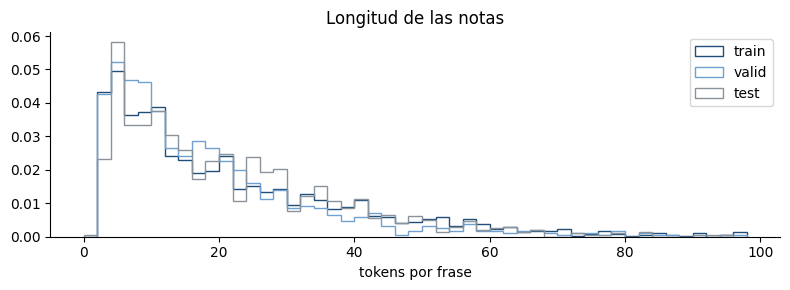

In [ ]:
%%por_corpus
lon = analisis_longitud(data, MAX_TOKENS)
display(pd.DataFrame({s: {**d["tokens"], "caract. media": d["caracteres"]["media"], "1-2 tokens": d["frases_1_2_tokens"],
                          f">{MAX_TOKENS} tokens": d[f"frases_>{MAX_TOKENS}_tokens"]} for s, d in lon.items()}).T)
fig, ax = plt.subplots(figsize=(8, 3))
for s, F in data.items():
    ax.hist([len(f) for f in F], bins=range(0, 100, 2), histtype="step", lw=1.5, density=True, label=s, color=COL[s])
ax.set_xlabel("tokens por frase"); ax.set_title("Longitud de las notas"); ax.legend()
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

### 1.2.4 Filtrado de duplicados (corpus normalizado)
Deja una sola aparición de cada frase, con la anotación mayoritaria, y elimina la fuga entre particiones. Si se indica `REPARTICIONAR`, las frases únicas se vuelven a repartir al azar.

El resultado (`CORPUS`) es el **corpus oficial** para el resto del trabajo: modelo base, Fase 2 y Fases 3 y 4.

In [ ]:
%%por_corpus
ent_dedup, log_dedup, limpio = None, None, None
if GUARDAR_DEDUP:
    limpio, log_dedup = deduplicar(data, variantes)
    if REPARTICIONAR:
        limpio = reparticionar(limpio, list(REPARTICIONAR), SEMILLA)
        for s in SPLITS: log_dedup[s]["despues"] = len(limpio[s])
        log_dedup["reparticionado"] = {"proporciones": list(REPARTICIONAR), "semilla": SEMILLA}
    (SALIDA / "corpus_dedup").mkdir(exist_ok=True)
    for s, F in limpio.items(): guardar_bio(F, SALIDA / "corpus_dedup" / f"{s}.bio")
    display(pd.DataFrame({s: {"antes": d["antes"], "después": d["despues"]} for s, d in log_dedup.items() if s in SPLITS}).T)
    print("Corpus limpio guardado en", SALIDA / "corpus_dedup")

#### ▸ Prostata

,antes,después
train,3106,1877
valid,929,402
test,991,402


Corpus limpio guardado en resultados/Prostata_20261023_0022/corpus_dedup


### 1.2.5 Distribución de etiquetas: relación entre ejemplos y entidades
¿Es proporcional el número de etiquetas a la cantidad de datos? Se compara el número de etiquetas BIO con el de tipos de entidad, se cuentan menciones, frases y formas distintas por tipo, y se calculan el ratio de desbalance (tipo más frecuente / menos frecuente) y la entropía normalizada (1 = distribución perfectamente equilibrada).

In [ ]:
%%por_corpus
ent = analisis_entidades(data, MIN_EJEMPLOS, MIN_TEST)
resumen = {k: ent[k] for k in ("n_etiquetas_BIO", "n_tipos", "tipos_sin_etiqueta_I", "frases_por_etiqueta_BIO",
                               "menciones_por_tipo_media", "menciones_por_tipo_mediana",
                               "ratio_desbalance_max_min", "entropia_normalizada", "pct_tokens_O", "tipos_con_alertas")}
display(pd.Series(resumen, name="corpus original").to_frame())
tabla = pd.DataFrame(ent["tabla"]).set_index("tipo")
tabla["alertas"] = tabla["alertas"].apply(lambda a: ", ".join(a) or "—")
tabla

#### ▸ Prostata

,corpus original
n_etiquetas_BIO,21
n_tipos,10
tipos_sin_etiqueta_I,[]
frases_por_etiqueta_BIO,147.9
menciones_por_tipo_media,721.7
menciones_por_tipo_mediana,691.5
ratio_desbalance_max_min,5.1
entropia_normalizada,0.939
pct_tokens_O,78.51
tipos_con_alertas,[]


,menciones_train,menciones_valid,menciones_test,frases_train_con_tipo,pct_menciones_train,formas_unicas_train,alertas
tipo,,,,,,,
FECHA,1263,319,401,893,17.50,660,—
CANCER,1207,296,364,767,16.72,127,—
TRATAMIENTO,1131,158,250,565,15.67,69,—
BIOMARCADOR,895,197,208,459,12.40,172,—
DOSIS,785,107,189,355,10.88,127,—
GLEASON,598,148,160,346,8.29,73,—
MEDICAMENTO,483,91,164,264,6.69,82,—
TNM,355,89,93,219,4.92,63,—
CIRUGIA,254,73,65,148,3.52,79,—


#### ▸ Prostata

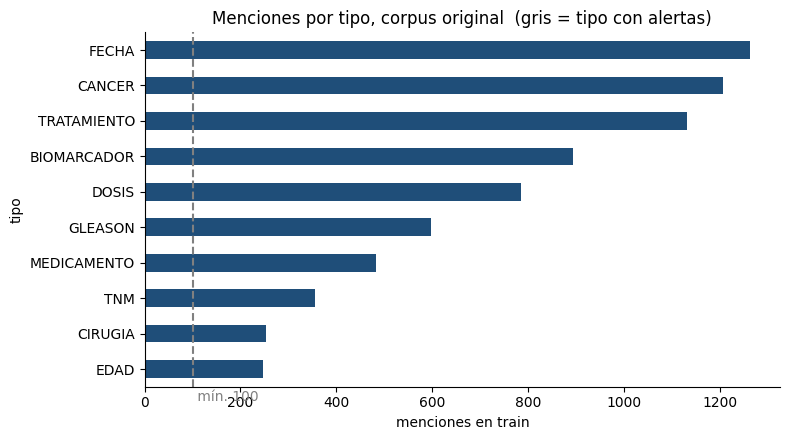

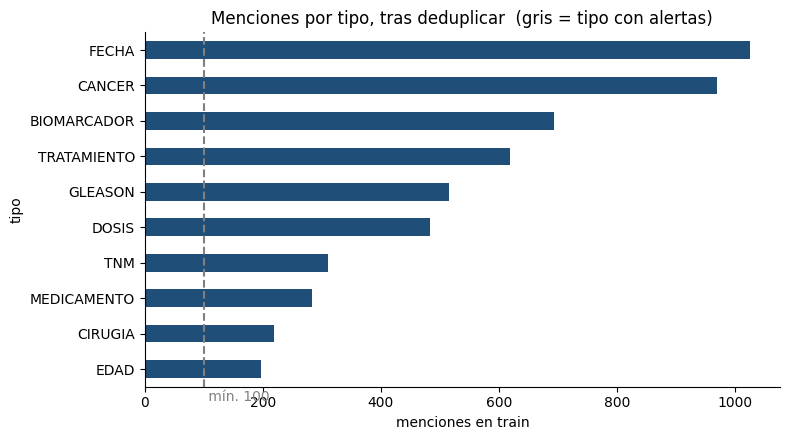

,original,deduplicado
ratio_desbalance_max_min,5.100,5.20
entropia_normalizada,0.939,0.94


Tipos con alertas tras deduplicar: ninguno


In [ ]:
%%por_corpus
def grafico_tipos(ent, titulo):
    t = pd.DataFrame(ent["tabla"]).set_index("tipo")["menciones_train"].sort_values()
    col = ["#8a929b" if x in ent["tipos_con_alertas"] else "#1f4e79" for x in t.index]
    ax = t.plot.barh(figsize=(8, 0.3 * len(t) + 1.5), color=col)
    ax.axvline(MIN_EJEMPLOS, ls="--", c="grey"); ax.text(MIN_EJEMPLOS, -0.9, f" mín. {MIN_EJEMPLOS}", color="grey")
    ax.set_xlabel("menciones en train"); ax.set_title(titulo + "  (gris = tipo con alertas)")
    ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

grafico_tipos(ent, "Menciones por tipo, corpus original")
if GUARDAR_DEDUP:
    ent_dedup = analisis_entidades(limpio, MIN_EJEMPLOS, MIN_TEST)
    grafico_tipos(ent_dedup, "Menciones por tipo, tras deduplicar")
    display(pd.DataFrame({"original": {k: ent[k] for k in ("ratio_desbalance_max_min", "entropia_normalizada")},
                          "deduplicado": {k: ent_dedup[k] for k in ("ratio_desbalance_max_min", "entropia_normalizada")}}))
    print("Tipos con alertas tras deduplicar:", ", ".join(ent_dedup["tipos_con_alertas"]) or "ninguno")

### 1.2.6 Label Consistency Score (LCS) y Class Balance Ratio (CBR)

**Definiciones usadas en este trabajo:**

| Métrica | Fórmula | Interpretación |
|---|---|---|
| **LCS-frase** | frases repetidas con una sola anotación / frases repetidas | 1 = todas las copias de una frase están anotadas igual |
| **LCS-tipo** | Σ menciones con el tipo mayoritario de su forma / total de menciones | 1 = cada expresión recibe siempre el mismo tipo |
| **LCS-marcado** | veces que una expresión se anota / veces que aparece (expresiones anotadas ≥3 veces) | 1 = las expresiones que suelen ser entidad se anotan siempre |
| **LCS (global)** | media de LCS-tipo y LCS-marcado | Resumen de consistencia. LCS-frase se reporta aparte, porque vale 1 de forma trivial tras deduplicar |
| **CBR** | menciones del tipo menos frecuente / menciones del más frecuente (en train) | 1 = balance perfecto; cerca de 0 = muy desbalanceado |

In [ ]:
%%por_corpus
import time
import collections, statistics as st

def label_consistency_score(corpus, min_apariciones=3):
    """Calcula LCS-frase, LCS-tipo, LCS-marcado y LCS global sobre un corpus {split: [frases]}."""
    frases = [f for F in corpus.values() for f in F]
    # LCS-frase
    variantes = collections.defaultdict(collections.Counter)
    for f in frases: variantes[texto(f)][etiquetas(f)] += 1
    repetidas = [c for c in variantes.values() if sum(c.values()) > 1]
    lcs_frase = sum(len(c) == 1 for c in repetidas) / len(repetidas) if repetidas else 1.0
    # LCS-tipo
    formas = collections.defaultdict(collections.Counter)
    for f in frases:
        for ty, a, b, tx in entidades(f): formas[tx.lower()][ty] += 1
    tot = sum(sum(c.values()) for c in formas.values())
    lcs_tipo = sum(c.most_common(1)[0][1] for c in formas.values()) / tot if tot else 1.0
    # LCS-marcado: expresiones anotadas >= min_apariciones veces, ¿cuántas veces aparecen sin anotar?
    anotadas = {k: sum(c.values()) for k, c in formas.items() if sum(c.values()) >= min_apariciones}
    largo = collections.defaultdict(set)
    for k in anotadas: largo[len(k.split())].add(k)
    sin_anotar = collections.Counter()
    for f in frases:
        w = [x.lower() for x, _ in f]; t = [x for _, x in f]
        for n, conj in largo.items():
            for j in range(len(w) - n + 1):
                g = " ".join(w[j:j + n])
                if g in conj and all(x == "O" for x in t[j:j + n]): sin_anotar[g] += 1
    total_ap = sum(anotadas.values()) + sum(sin_anotar.values())
    lcs_marcado = sum(anotadas.values()) / total_ap if total_ap else 1.0
    return {"LCS": round((lcs_tipo + lcs_marcado) / 2, 4), "LCS_frase": round(lcs_frase, 4),
            "LCS_tipo": round(lcs_tipo, 4), "LCS_marcado": round(lcs_marcado, 4),
            "frases_repetidas": len(repetidas), "expresiones_evaluadas_marcado": len(anotadas)}

def class_balance_ratio(corpus, split="train"):
    c = collections.Counter(e[0] for f in corpus[split] for e in entidades(f))
    return {"CBR": round(min(c.values()) / max(c.values()), 4),
            "tipo_min": min(c, key=c.get), "tipo_max": max(c, key=c.get),
            "menciones_min": min(c.values()), "menciones_max": max(c.values())}

# Corpus oficial para el resto del trabajo: deduplicado y reparticionado (si GUARDAR_DEDUP), si no el original
CORPUS = limpio if GUARDAR_DEDUP else data
metricas_base = pd.DataFrame({
    "original":     {**label_consistency_score(data),   **class_balance_ratio(data)},
    "deduplicado":  {**label_consistency_score(CORPUS), **class_balance_ratio(CORPUS)},
})
metricas_base

#### ▸ Prostata

,original,deduplicado
LCS,0.9527,0.9563
LCS_frase,0.9637,1.0
LCS_tipo,0.9994,0.9995
LCS_marcado,0.9059,0.913
frases_repetidas,1047,0
expresiones_evaluadas_marcado,708,541
CBR,0.1948,0.1922
tipo_min,EDAD,EDAD
tipo_max,FECHA,FECHA
menciones_min,246,197


### 1.2.7 Documento de diagnóstico
Genera `informe.md` y `diagnostico.json` con todas las métricas de las secciones 1.2.1 a 1.2.5.

In [ ]:
%%por_corpus
def tabla_md(df):
    df = df.reset_index() if df.index.name or not isinstance(df.index, pd.RangeIndex) else df
    fmt = lambda x: int(x) if isinstance(x, float) and x.is_integer() else x
    df = df.apply(lambda col: col.map(fmt))
    return md_tabla(df.astype(str).to_dict("records"), [str(c) for c in df.columns])

partes = [f"# Documento de diagnóstico del corpus: {NOMBRE}", f"_Generado: {dt.datetime.now():%Y-%m-%d %H:%M}_", "",
          "Archivos: " + ", ".join(f"`{s}` = {p.name}" for s, p in rutas.items()), ""]
if malas:
    partes += ["**Líneas mal formadas:** " + "; ".join(f"{m['split']} línea {m['linea']} `{m['contenido']}` ({m['accion']})" for m in malas), ""]
partes += ["## 1. Duplicados por partición", "",
           tabla_md(pd.DataFrame(dup["por_split"]).T.drop(columns="mas_repetidas").rename_axis("split")),
           "## 2. Fuga entre particiones", "", tabla_md(pd.DataFrame(dup["fuga"]).T.rename_axis("cruce")),
           f"**Frases con anotación contradictoria:** {dup['n_conflictos']} ({dup['pct_conflictos_sobre_unicas']} % de las frases únicas).", "",
           tabla_md(pd.DataFrame(dup["conflictos"][:10])[["frase", "apariciones", "diferencias"]]) if dup["conflictos"] else "",
           "## 3. Longitud de las notas (tokens por frase)", "",
           tabla_md(pd.DataFrame({s: {**d["tokens"], "1-2 tokens": d["frases_1_2_tokens"]} for s, d in lon.items()}).T.rename_axis("split"))]
if log_dedup:
    partes += ["## 4. Corpus normalizado (deduplicado)", "",
               tabla_md(pd.DataFrame({s: {"antes": d["antes"], "después": d["despues"]} for s, d in log_dedup.items() if s in SPLITS}).T.rename_axis("split"))]
partes += ["## 5. Distribución de etiquetas", "",
           f"- Etiquetas BIO: **{ent['n_etiquetas_BIO']}**; tipos de entidad: **{ent['n_tipos']}**.",
           f"- Ratio de desbalance: **{ent['ratio_desbalance_max_min']}**; entropía normalizada: **{ent['entropia_normalizada']}**.",
           f"- Tipos con alertas: {', '.join(ent['tipos_con_alertas']) or 'ninguno'}.", "",
           tabla_md(pd.DataFrame(ent["tabla"]).assign(alertas=lambda d: d["alertas"].apply(lambda a: ", ".join(a) or "—")))]
(SALIDA / "informe.md").write_text("\n".join(partes) + "\n", encoding="utf-8")
(SALIDA / "diagnostico.json").write_text(json.dumps({"corpus": NOMBRE, "archivos": {s: str(p) for s, p in rutas.items()},
    "lineas_mal_formadas": lineas_malas, "duplicados": dup, "longitud": lon, "entidades": ent, "entidades_dedup": ent_dedup,
    "deduplicacion": log_dedup}, ensure_ascii=False, indent=1, default=str), encoding="utf-8")
print("Documento de diagnóstico guardado en:", (SALIDA / "informe.md").resolve())

#### ▸ Prostata

Documento de diagnóstico guardado en: /content/resultados/Prostata_20261023_0022/informe.md


## 1.3 Comparación con CoNLL-2002 (y PharmaCoNER, CANTEMIST) y modelo base
### 1.3.1 Comparación de estructura y balance
Se calculan las mismas métricas para tu corpus y para los corpus de referencia cargados en 1.1.2:
- **Estructura:** tamaño, longitud de frase y densidad de entidades.
- **Balance:** CBR, ratio de desbalance y entropía.
- **Consistencia:** LCS.

En los corpus con un solo tipo de entidad (CANTEMIST), el CBR y la entropía valen 1 de forma trivial.

In [ ]:
%%por_corpus
def perfil_corpus(corpus, nombre):
    ent_ = analisis_entidades(corpus, MIN_EJEMPLOS, MIN_TEST)
    lon_ = analisis_longitud(corpus, MAX_TOKENS)
    fr = {s: len(F) for s, F in corpus.items()}
    n_ent = sum(len(entidades(f)) for F in corpus.values() for f in F)
    n_tok = sum(len(f) for F in corpus.values() for f in F)
    return {"corpus": nombre, "frases train/valid/test": f"{fr.get('train',0)}/{fr.get('valid',0)}/{fr.get('test',0)}",
            "tokens": n_tok, "tipos de entidad": ent_["n_tipos"], "etiquetas BIO": ent_["n_etiquetas_BIO"],
            "entidades": n_ent, "entidades / 100 tokens": round(100 * n_ent / n_tok, 1),
            "% tokens O": ent_["pct_tokens_O"], "long. mediana (train)": lon_["train"]["tokens"]["mediana"],
            "long. p99 (train)": lon_["train"]["tokens"]["p99"],
            "ratio desbalance": ent_["ratio_desbalance_max_min"], "entropía normalizada": ent_["entropia_normalizada"],
            **{k: v for k, v in class_balance_ratio(corpus).items() if k == "CBR"},
            **{k: v for k, v in label_consistency_score(corpus).items() if k in ("LCS", "LCS_tipo", "LCS_marcado")}}

perfiles = [perfil_corpus(data, f"{NOMBRE} (original)"), perfil_corpus(CORPUS, f"{NOMBRE} (deduplicado)")]
for nombre_ref, corp_ref in REF.items():
    if nombre_ref not in _PERFIL_REF:
        print(f"Calculando métricas de {nombre_ref}...")
        _PERFIL_REF[nombre_ref] = perfil_corpus(corp_ref, nombre_ref)
    perfiles.append(_PERFIL_REF[nombre_ref])
comparacion = pd.DataFrame(perfiles).set_index("corpus").T
comparacion.to_csv(SALIDA / "1_3_comparacion_corpus_referencia.csv", encoding="utf-8-sig")
comparacion

#### ▸ Prostata

Calculando métricas de CoNLL-2002...
Calculando métricas de PharmaCoNER...
Calculando métricas de CANTEMIST...


corpus,Prostata (original),Prostata (deduplicado),CoNLL-2002,PharmaCoNER,CANTEMIST
frases train/valid/test,3106/929/991,1877/402/402,8323/1915/1517,8129/3787/3952,19397/18165/11168
tokens,105597,68100,369171,401136,1078880
tipos de entidad,10,10,4,4,1
etiquetas BIO,21,21,9,9,3
entidades,10736,7676,26709,7526,15891
entidades / 100 tokens,10.2,11.3,7.2,1.9,1.5
% tokens O,78.51,75.33,87.39,97.68,96.6
long. mediana (train),15.0,20.0,34.0,22.0,19.0
long. p99 (train),95.9,97.2,76.0,78.0,76.0
ratio desbalance,5.1,5.2,3.4,95.1,1.0


#### ▸ Prostata

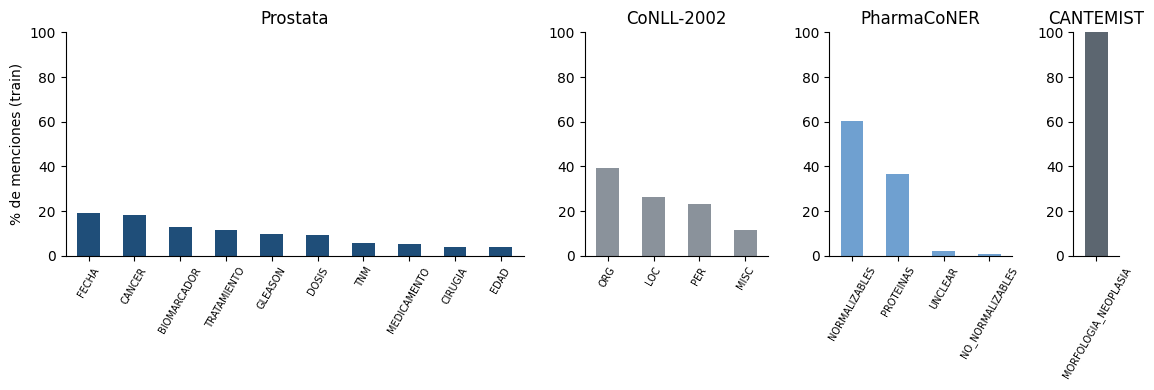

In [ ]:
%%por_corpus
# Distribución de tipos (% de menciones en train) de cada corpus
corpus_graf = [(NOMBRE, CORPUS, "#1f4e79")] + [(n, c, col) for (n, c), col in zip(REF.items(), ["#8a929b", "#6fa0d0", "#5c6670"])]
anchos = [max(1, len({e[0] for f in c["train"] for e in entidades(f)})) for _, c, _ in corpus_graf]
fig, axs = plt.subplots(1, len(corpus_graf), figsize=(3 + 0.45 * sum(anchos), 4), gridspec_kw={"width_ratios": anchos})
axs = axs if len(corpus_graf) > 1 else [axs]
for ax, (tit, corp, col) in zip(axs, corpus_graf):
    c = collections.Counter(e[0] for f in corp["train"] for e in entidades(f))
    s = pd.Series(c).sort_values(ascending=False) / sum(c.values()) * 100
    s.plot.bar(ax=ax, color=col); ax.set_title(tit); ax.set_ylim(0, 100)
    ax.spines[["top", "right"]].set_visible(False); ax.tick_params(axis="x", rotation=60, labelsize=7)
axs[0].set_ylabel("% de menciones (train)")
plt.tight_layout(); plt.savefig(SALIDA / "1_3_distribucion_tipos_vs_referencias.png", dpi=130); plt.show()

### 1.3.2 Entrenamiento del modelo base y F-score (global y por etiqueta)
Fine-tuning de un modelo tipo BERT para NER sobre el **corpus oficial con las anotaciones humanas** (condición A de la Fase 4). Las métricas se calculan a nivel de entidad (coincidencia exacta de inicio, fin y tipo), igual que `seqeval`.

- **Requisitos:** `pip install transformers accelerate torch`, y una GPU para que tarde minutos y no horas (en Colab: *Entorno de ejecución → Cambiar tipo → GPU*).
- **Salida:** F1 global (micro y macro) y por etiqueta, más una fila en `registro_experimentos.csv`. La Fase 3 reutiliza la misma función con el corpus depurado.

**F-score que se obtiene aquí** (sobre el test, con las etiquetas humanas):
- **F1 global**: *micro* (todas las entidades juntas) y *macro* (media de los tipos, da el mismo peso a los tipos poco frecuentes).
- **F1 por etiqueta**: precisión, recall, F1 y soporte de cada tipo de entidad, con su gráfico.

Con `ENTRENAR_BASELINE = "auto"`, el entrenamiento se hace solo cuando hay GPU. Sin GPU la celda explica cómo activarla.

In [ ]:
def metricas_ner(gold_tags, pred_tags):
    """Métricas a nivel de entidad (exactas). gold_tags y pred_tags: listas de listas de etiquetas BIO."""
    def spans(tags):
        return {(ty, a, b) for ty, a, b, _ in entidades([("x", t) for t in tags])}
    tp, fp, fn = collections.Counter(), collections.Counter(), collections.Counter()
    for g, p in zip(gold_tags, pred_tags):
        G, P = spans(g), spans(p)
        for ty, *_ in G & P: tp[ty] += 1
        for ty, *_ in P - G: fp[ty] += 1
        for ty, *_ in G - P: fn[ty] += 1
    def prf(t, f_p, f_n):
        p = t / (t + f_p) if t + f_p else 0.0; r = t / (t + f_n) if t + f_n else 0.0
        return p, r, (2 * p * r / (p + r) if p + r else 0.0)
    por_tipo = {}
    for ty in sorted(set(tp) | set(fp) | set(fn)):
        p, r, f = prf(tp[ty], fp[ty], fn[ty])
        por_tipo[ty] = {"precision": round(p, 4), "recall": round(r, 4), "f1": round(f, 4), "soporte": tp[ty] + fn[ty]}
    P_, R_, F_ = prf(sum(tp.values()), sum(fp.values()), sum(fn.values()))
    macro = st.mean([d["f1"] for d in por_tipo.values()]) if por_tipo else 0.0
    return {"precision": round(P_, 4), "recall": round(R_, 4), "f1_micro": round(F_, 4),
            "f1_macro": round(macro, 4), "por_tipo": por_tipo}

def registrar_experimento(fila, ruta=Path("registro_experimentos.csv")):
    previo = pd.read_csv(ruta, encoding="utf-8-sig") if ruta.exists() else pd.DataFrame()
    df = pd.concat([previo, pd.DataFrame([fila])], ignore_index=True)     # une columnas aunque cambien los tipos
    df.to_csv(ruta, index=False, encoding="utf-8-sig")
    return df

def entrenar_ner(corpus, nombre_exp, modelo=MODELO_BERT, epochs=EPOCHS, lr=LR, batch=BATCH,
                 max_len=MAX_LEN, semilla=SEMILLA, carpeta_salida=None):
    """Entrena un modelo de NER (token classification) y lo evalúa en corpus['test'].
    Devuelve (metricas_test, predicciones_test)."""
    import numpy as np, torch
    from transformers import (AutoTokenizer, AutoModelForTokenClassification, DataCollatorForTokenClassification,
                              TrainingArguments, Trainer, set_seed)
    set_seed(semilla)
    etiquetas = ["O"] + sorted({t for F in corpus.values() for f in F for _, t in f} - {"O"})
    l2i = {l: i for i, l in enumerate(etiquetas)}
    try:
        tok = AutoTokenizer.from_pretrained(modelo, add_prefix_space=True)
    except Exception:
        tok = AutoTokenizer.from_pretrained(modelo)

    def codificar(frases):
        enc = tok([[w for w, _ in f] for f in frases], is_split_into_words=True,
                  truncation=True, max_length=max_len)
        items = []
        for i, f in enumerate(frases):
            wid, prev, lab = enc.word_ids(i), None, []
            for w in wid:
                lab.append(-100 if w is None or w == prev else l2i[f[w][1]]); prev = w
            items.append({"input_ids": enc["input_ids"][i], "attention_mask": enc["attention_mask"][i], "labels": lab})
        return items, enc

    tr, _ = codificar(corpus["train"]); va, _ = codificar(corpus["valid"]); te, enc_te = codificar(corpus["test"])
    mdl = AutoModelForTokenClassification.from_pretrained(
        modelo, num_labels=len(etiquetas), id2label=dict(enumerate(etiquetas)), label2id=l2i,
        ignore_mismatched_sizes=True)

    def a_etiquetas(pred_ids, items):
        out = []
        for p, it in zip(pred_ids, items):
            out.append([etiquetas[pi] for pi, li in zip(p, it["labels"]) if li != -100])
        return out

    def compute_metrics(ev):
        logits, labels = ev
        pred = logits.argmax(-1)
        g = [[etiquetas[l] for l in fila if l != -100] for fila in labels]
        p = [[etiquetas[pi] for pi, l in zip(pf, lf) if l != -100] for pf, lf in zip(pred, labels)]
        m = metricas_ner(g, p)
        return {"f1": m["f1_micro"], "f1_macro": m["f1_macro"], "precision": m["precision"], "recall": m["recall"]}

    salida = Path(carpeta_salida or (SALIDA / "modelos" / nombre_exp))
    kw = dict(output_dir=str(salida), learning_rate=lr, per_device_train_batch_size=batch,
              per_device_eval_batch_size=batch, num_train_epochs=epochs, weight_decay=0.01,
              save_strategy="epoch", load_best_model_at_end=True, metric_for_best_model="f1",
              save_total_limit=1, logging_steps=50, seed=semilla, report_to="none",
              fp16=torch.cuda.is_available())
    try:
        args_tr = TrainingArguments(eval_strategy="epoch", **kw)
    except TypeError:                                   # versiones antiguas de transformers
        args_tr = TrainingArguments(evaluation_strategy="epoch", **kw)
    trainer = Trainer(model=mdl, args=args_tr, train_dataset=tr, eval_dataset=va,
                      data_collator=DataCollatorForTokenClassification(tok), compute_metrics=compute_metrics)
    t0 = time.time(); trainer.train(); minutos = (time.time() - t0) / 60

    pred = trainer.predict(te).predictions.argmax(-1)
    pred_tags = a_etiquetas(pred, te)
    # las palabras truncadas (frases > max_len subpalabras) se predicen como O
    pred_tags = [p + ["O"] * (len(f) - len(p)) for p, f in zip(pred_tags, corpus["test"])]
    gold_tags = [[t for _, t in f] for f in corpus["test"]]
    m = metricas_ner(gold_tags, pred_tags)

    fila = {"fecha": dt.datetime.now().strftime("%Y-%m-%d %H:%M"), "experimento": nombre_exp, "corpus": NOMBRE,
            "modelo": modelo, "epochs": epochs, "lr": lr, "batch": batch, "max_len": max_len, "semilla": semilla,
            "frases_train": len(corpus["train"]), "minutos": round(minutos, 1),
            "precision": m["precision"], "recall": m["recall"], "f1_micro": m["f1_micro"], "f1_macro": m["f1_macro"],
            **{f"f1_{ty}": d["f1"] for ty, d in m["por_tipo"].items()},
            **{k: v for k, v in label_consistency_score(corpus).items() if k == "LCS"},
            **{k: v for k, v in class_balance_ratio(corpus).items() if k == "CBR"}}
    registro = registrar_experimento(fila)
    return m, pred_tags, registro

#### ▸ Prostata

config.json:   0%|          | 0.00/613 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.25k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.17M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/521k [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

**Baseline (PlanTL-GOB-ES/bsc-bio-ehr-es)**: F1 micro = 0.9496, F1 macro = 0.9434

,precision,recall,f1,soporte
FECHA,0.9910,1.0000,0.9955,221.0
CANCER,0.9598,0.9773,0.9685,220.0
TRATAMIENTO,0.9593,0.9483,0.9538,174.0
GLEASON,0.9250,0.9487,0.9367,117.0
BIOMARCADOR,0.9138,0.9636,0.9381,110.0
DOSIS,0.8230,0.8611,0.8416,108.0
TNM,0.8941,0.9500,0.9212,80.0
MEDICAMENTO,0.9697,0.9697,0.9697,66.0
EDAD,1.0000,1.0000,1.0000,40.0
CIRUGIA,0.9091,0.9091,0.9091,33.0


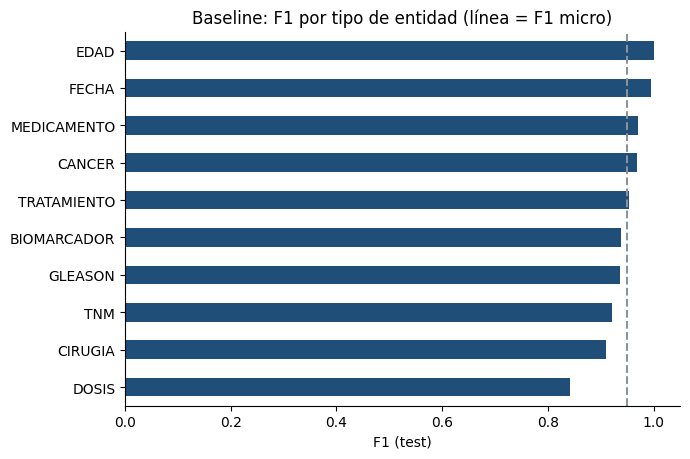

In [ ]:
%%por_corpus
resultado_base = None
try:
    import torch; HAY_GPU = torch.cuda.is_available()
except ImportError:
    HAY_GPU = False
ENTRENAR = ENTRENAR_BASELINE is True or (ENTRENAR_BASELINE == "auto" and HAY_GPU)
if ENTRENAR:
    if not HAY_GPU: print("Aviso: sin GPU el entrenamiento puede tardar horas.")
    m_base, pred_base, registro = entrenar_ner(CORPUS, f"baseline_{NOMBRE}")
    resultado_base = m_base
    display(Markdown(f"**Baseline ({MODELO_BERT})**: F1 micro = {m_base['f1_micro']}, F1 macro = {m_base['f1_macro']}"))
    tabla_base = pd.DataFrame(m_base["por_tipo"]).T.sort_values("soporte", ascending=False)
    display(tabla_base)
    tabla_base.to_csv(SALIDA / "baseline_f1_por_tipo.csv", encoding="utf-8-sig")
    ax = tabla_base["f1"].sort_values().plot.barh(figsize=(7, 0.35 * len(tabla_base) + 1.2), color="#1f4e79")
    ax.axvline(m_base["f1_micro"], ls="--", c="#8a929b"); ax.set_xlabel("F1 (test)")
    ax.set_title("Baseline: F1 por tipo de entidad (línea = F1 micro)"); ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout(); plt.savefig(SALIDA / "baseline_f1_por_tipo.png", dpi=130); plt.show()
    import gc; gc.collect(); torch.cuda.empty_cache() if HAY_GPU else None     # deja la GPU libre para el siguiente corpus y Ollama
else:
    display(Markdown(
        "**El F-score no se ha calculado porque el modelo base no se entrenó.** "
        + ("No hay GPU disponible. " if not HAY_GPU else "") +
        "Para obtener el F1 global y por etiqueta: en Colab, *Entorno de ejecución → Cambiar tipo de entorno → GPU*, "
        "y vuelve a ejecutar el cuaderno (con `ENTRENAR_BASELINE = \"auto\"` entrena solo), "
        "o pon `ENTRENAR_BASELINE = True` para forzarlo."))

### 1.3.3 Informe de métricas de línea base
Resume en una tabla los resultados esperados de la Fase 1: F-score global (micro y macro) y por etiqueta del modelo base, LCS y CBR. Se guarda en `1_3_metricas_linea_base.csv`.

In [ ]:
%%por_corpus
linea_base = {"corpus": NOMBRE, "frases train/valid/test": "/".join(str(len(CORPUS[s])) for s in ("train", "valid", "test")),
              **{k: v for k, v in label_consistency_score(CORPUS).items() if k.startswith("LCS")},
              **class_balance_ratio(CORPUS)}
if resultado_base:
    linea_base.update({"modelo base": MODELO_BERT, "F1 micro": resultado_base["f1_micro"],
                       "F1 macro": resultado_base["f1_macro"],
                       **{f"F1 {ty}": d["f1"] for ty, d in resultado_base["por_tipo"].items()}})
else:
    linea_base["modelo base"] = "no entrenado (ENTRENAR_BASELINE = False)"
linea_base = pd.Series(linea_base, name="línea base")
linea_base.to_csv(SALIDA / "1_3_metricas_linea_base.csv", encoding="utf-8-sig")
linea_base.to_frame()

#### ▸ Prostata

,línea base
corpus,Prostata
frases train/valid/test,1877/402/402
LCS,0.9563
LCS_frase,1.0
LCS_tipo,0.9995
LCS_marcado,0.913
CBR,0.1922
tipo_min,EDAD
tipo_max,FECHA
menciones_min,197


---
# FASE 2: Filtrado y anotación automática con LLMs generativos
**Objetivo específico 2:** diseñar e implementar scripts de filtrado y anotación automática con LLMs generativos.

**Resultados esperados:** scripts documentados y reproducibles, y un corpus biomédico depurado y enriquecido, listo para entrenar.

**Cómo funciona:** a cada LLM se le da el texto de una frase **sin etiquetas**. El LLM devuelve las entidades en JSON, el script las convierte a BIO y las compara con la anotación humana. De esa comparación salen:

1. Las **métricas de cada LLM** frente a la anotación humana (2.2.4).
2. Las **correcciones por consenso** entre LLMs (2.2.5).
3. El **corpus depurado** (train y valid). **El test conserva las etiquetas humanas**; ahí la anotación de los LLMs solo sirve para medir su rendimiento (condición B de la Fase 4).

## 2.1 Diseño del esquema de prompts para depuración y anotación
### 2.1.1 Guía de etiquetas
Es la definición de cada tipo de entidad que verá el LLM. Los ejemplos se extraen automáticamente del train. Las definiciones son editables: ajústalas a la guía de anotación original si la tienes.

In [ ]:
%%por_corpus
DEFINICIONES = {
    # --- Próstata
    "EDAD": "Edad del paciente, incluida la unidad (p. ej. '72 años').",
    "FECHA": "Fechas explícitas o parciales (día, mes, año), incluidas expresiones como 'abril del 2018'.",
    "CANCER": "Diagnóstico o descripción del tumor o neoplasia, con su morfología y localización (p. ej. 'adenocarcinoma de próstata', 'lesiones metastásicas').",
    "TRATAMIENTO": "Tratamientos oncológicos no farmacológicos o técnicas: radioterapia, IMRT, SBRT, hormonoterapia, Lu-177-PSMA, etc.",
    "BIOMARCADOR": "Biomarcadores y su valor cuando aparece (p. ej. 'PSA 8,5', 'PSA', 'testosterona').",
    "DOSIS": "Dosis o esquema de dosis de un fármaco o de radioterapia (p. ej. '60 Gy', '8 mg', '200mCi', 'segunda dosis').",
    "GLEASON": "Puntuación de Gleason y grupo ISUP (p. ej. 'GLEASON SCORE 3+3', '4+5').",
    "MEDICAMENTO": "Nombre de un medicamento o principio activo (p. ej. 'enzalutamida', 'ondansetron').",
    "TNM": "Estadificación TNM (p. ej. 'T3N0M1b', 'cT4 N1 M1').",
    "CIRUGIA": "Procedimientos quirúrgicos (p. ej. 'prostatectomía radical', 'herniorrafías').",
    # --- Pulmón
    "CANCER_CONCEPT": "Diagnóstico, tipo o descripción del cáncer (p. ej. 'adenocarcinoma de pulmón', 'cancer de mama').",
    "CHEMOTHERAPY": "Mención de quimioterapia como tratamiento (p. ej. 'QT', 'quimioterapia').",
    "RADIOTHERAPY": "Mención de radioterapia como tratamiento (p. ej. 'RT', 'radioterapia').",
    "SURGERY": "Procedimientos quirúrgicos (p. ej. 'lobectomía', 'resección').",
    "DRUG": "Nombre de un fármaco o principio activo (p. ej. 'pemetrexed', 'carboplatino').",
    "DATE": "Fechas explícitas (p. ej. 'abril de 2019', 'Octubre-14').",
    "IMPLICIT_DATE": "Referencias temporales relativas o implícitas (p. ej. 'hace 2 meses', 'el año pasado').",
    "INTERVAL": "Duración o intervalo de tiempo (p. ej. 'durante 6 meses').",
    "FREQ": "Frecuencia o periodicidad de un tratamiento (p. ej. 'cada 21 días', 'día 1 y 8', 'trisemanal').",
    "QUANTITY": "Valor numérico de una medida o cantidad (p. ej. '70' en '70 años', '4' en '4 ciclos').",
    "METRIC": "Unidad o magnitud que acompaña a una cantidad (p. ej. 'años', 'mg', 'ciclos', 'Gy', 'AUC').",
    "OCURRENCE_EVENT": "Evento clínico que ocurre al paciente (p. ej. 'diagnosticada', 'progresión', 'inicio').",
    "STAGE": "Estadio de la enfermedad (p. ej. 'estadio IIIB', 'IV').",
    "SMOKER_STATUS": "Hábito tabáquico (p. ej. 'fumador', 'exfumador', 'no fumador').",
    "FAMILY": "Familiar mencionado en antecedentes (p. ej. 'abuela materna', 'padre').",
}

def construir_guia(corpus, n_ejemplos=5):
    """Tipos del corpus con su definición y las expresiones más frecuentes en train."""
    formas = collections.defaultdict(collections.Counter)
    for f in corpus["train"]:
        for ty, a, b, tx in entidades(f): formas[ty][tx] += 1
    guia = {}
    for ty in sorted(formas):
        guia[ty] = {"definicion": DEFINICIONES.get(ty, f"Entidad de tipo {ty}."),
                    "ejemplos": [tx for tx, _ in formas[ty].most_common(n_ejemplos)]}
    return guia

GUIA = construir_guia(CORPUS)
TIPOS = sorted(GUIA)
pd.DataFrame(GUIA).T

#### ▸ Prostata

,definicion,ejemplos
BIOMARCADOR,"Biomarcadores y su valor cuando aparece (p. ej. 'PSA 8,5', 'PSA', 'testosterona').","[psa, PSA, PSMA, creatinina, PSA en 9,9 ng/dl]"
CANCER,"Diagnóstico o descripción del tumor o neoplasia, con su morfología y localización (p. ej. 'adenocarcinoma de próstat...","[adenocarcinoma, adenocarcinoma de próstata, lesiones metastásicas, ca de próstata, Adenocarcinoma de próstata]"
CIRUGIA,"Procedimientos quirúrgicos (p. ej. 'prostatectomía radical', 'herniorrafías').","[Prostatectomía, prostatectomía, prostatectomía radical, linfadenectomía, apendicetomía]"
DOSIS,"Dosis o esquema de dosis de un fármaco o de radioterapia (p. ej. '60 Gy', '8 mg', '200mCi', 'segunda dosis').","[6 Mev, 5 fracciones, 8 Gy, 4 ciclos, 20 fracciones de 2,88 Gy]"
EDAD,"Edad del paciente, incluida la unidad (p. ej. '72 años').","[72 años, 70 años, 64 años, 76 años, 71 años]"
FECHA,"Fechas explícitas o parciales (día, mes, año), incluidas expresiones como 'abril del 2018'.","[2021, 2014, 2018, 2012, 2008]"
GLEASON,"Puntuación de Gleason y grupo ISUP (p. ej. 'GLEASON SCORE 3+3', '4+5').","[Gleason 4+4, Gleason 3+4, Gleason 3+3, Gleason score 3+3, Gleason score 3+4]"
MEDICAMENTO,"Nombre de un medicamento o principio activo (p. ej. 'enzalutamida', 'ondansetron').","[goserelina, leuprolide, abiraterona, bicalutamida, docetaxel]"
TNM,"Estadificación TNM (p. ej. 'T3N0M1b', 'cT4 N1 M1').","[ct2nxm0, cN0, M0, ct4n1m0, cT2NxM0]"
TRATAMIENTO,"Tratamientos oncológicos no farmacológicos o técnicas: radioterapia, IMRT, SBRT, hormonoterapia, Lu-177-PSMA, etc.","[IMRT, RT tipo IMRT, SBRT, bloqueo hormonal, radioterapia]"


### 2.1.2 Ejemplos resueltos (*few-shot*)
Se eligen automáticamente frases del train que cubran el mayor número de tipos. Estas frases no se incluyen en la muestra que se anota.

In [ ]:
%%por_corpus
import random

def a_json(frase):
    return [{"texto": tx, "tipo": ty} for ty, a, b, tx in entidades(frase)]

def elegir_few_shot(corpus, n, semilla=SEMILLA, max_tokens=40):
    cand = [f for f in corpus["train"] if 5 <= len(f) <= max_tokens and entidades(f)]
    random.Random(semilla).shuffle(cand)
    elegidos, cubiertos = [], set()
    for _ in range(n):
        mejor = max(cand, key=lambda f: len({e[0] for e in entidades(f)} - cubiertos), default=None)
        if mejor is None: break
        elegidos.append(mejor); cubiertos |= {e[0] for e in entidades(mejor)}; cand.remove(mejor)
    return elegidos

FEW_SHOT = elegir_few_shot(CORPUS, N_FEW_SHOT)
for f in FEW_SHOT:
    print("Texto:", " ".join(w for w, _ in f)); print("JSON :", json.dumps(a_json(f), ensure_ascii=False)); print()

#### ▸ Prostata

Texto: Paciente de 60 años con adenocarcinoma de próstata - Gleason 3+4 3 + 4 , ct2nxm0 - psai : 20 ng/ml ng / ml , con tratamiento de bloqueo hormonal bicalutamida y goserelina .
JSON : [{"texto": "60 años", "tipo": "EDAD"}, {"texto": "adenocarcinoma de próstata", "tipo": "CANCER"}, {"texto": "Gleason 3+4", "tipo": "GLEASON"}, {"texto": "ct2nxm0", "tipo": "TNM"}, {"texto": "20 ng/ml", "tipo": "BIOMARCADOR"}, {"texto": "bloqueo hormonal", "tipo": "TRATAMIENTO"}, {"texto": "bicalutamida", "tipo": "MEDICAMENTO"}, {"texto": "goserelina", "tipo": "MEDICAMENTO"}]

Texto: Tratamiento : Prostatectomía radical 2014 , RDT 35 fracciones + Hormonoterapia 2015 : Leuprolide 45 mg FI 2018 ultima aplicación 12/2023 , Enzalutamida FI 2022 .
JSON : [{"texto": "Prostatectomía radical", "tipo": "CIRUGIA"}, {"texto": "2014", "tipo": "FECHA"}, {"texto": "RDT", "tipo": "TRATAMIENTO"}, {"texto": "35 fracciones", "tipo": "DOSIS"}, {"texto": "Hormonoterapia", "tipo": "TRATAMIENTO"}, {"texto": "2015", "tipo": "

### 2.1.3 Prompts de anotación y de revisión
Hay dos modos:

- **`anotacion` (recomendado):** el LLM solo ve el texto y anota desde cero. Mide la cobertura sin influir al modelo.
- **`revision`:** el LLM ve el texto y la anotación actual, y devuelve la versión corregida. Es más barato de validar, pero tiende a dar la razón a la etiqueta existente.

Cada prompt tiene una versión (`VERSION_PROMPT`). Si lo cambias, sube la versión: así la caché no mezcla respuestas de prompts distintos y el experimento queda documentado.

In [ ]:
%%por_corpus
VERSION_PROMPT = "v1"

def prompt_sistema(guia, modo=MODO_PROMPT):
    tipos = "\n".join(f"- {ty}: {d['definicion']} Ejemplos: {', '.join(repr(x) for x in d['ejemplos'])}"
                      for ty, d in guia.items())
    tarea = ("Identifica TODAS las entidades del texto." if modo == "anotacion" else
             "Revisa la anotación propuesta y devuelve la lista COMPLETA y CORREGIDA de entidades "
             "(añade las que falten, corrige tipos o límites y elimina las incorrectas).")
    return f"""Eres un anotador experto en Reconocimiento de Entidades Nombradas (NER) clínicas en español.
{tarea}

Tipos de entidad permitidos (usa SOLO estos):
{tipos}

Reglas:
1. Copia el texto de cada entidad EXACTAMENTE como aparece, respetando los espacios entre tokens.
2. Las entidades no se solapan. Si una expresión aparece varias veces, inclúyela una vez por aparición.
3. No incluyas signos de puntuación al inicio o al final de una entidad.
4. Si no hay entidades, devuelve una lista vacía.
5. Responde SOLO con JSON válido, con este formato: {{"entidades": [{{"texto": "...", "tipo": "..."}}]}}"""

def prompt_usuario(frase, modo=MODO_PROMPT, few_shot=FEW_SHOT):
    partes = []
    for f in few_shot:
        ej = {"texto": " ".join(w for w, _ in f)}
        if modo == "revision": ej["anotacion_actual"] = a_json(f)
        partes.append(f"Entrada: {json.dumps(ej, ensure_ascii=False)}\nSalida: {json.dumps({'entidades': a_json(f)}, ensure_ascii=False)}")
    entrada = {"texto": " ".join(w for w, _ in frase)}
    if modo == "revision": entrada["anotacion_actual"] = a_json(frase)
    partes.append(f"Entrada: {json.dumps(entrada, ensure_ascii=False)}\nSalida:")
    return "\n\n".join(partes)

SISTEMA_F2 = prompt_sistema(GUIA)
print(SISTEMA_F2[:1500], "\n...\n")
print("---- Ejemplo de prompt de usuario ----")
print(prompt_usuario(CORPUS["valid"][0])[-600:])

#### ▸ Prostata

Eres un anotador experto en Reconocimiento de Entidades Nombradas (NER) clínicas en español.
Identifica TODAS las entidades del texto.

Tipos de entidad permitidos (usa SOLO estos):
- BIOMARCADOR: Biomarcadores y su valor cuando aparece (p. ej. 'PSA 8,5', 'PSA', 'testosterona'). Ejemplos: 'psa', 'PSA', 'PSMA', 'creatinina', 'PSA en 9,9 ng/dl'
- CANCER: Diagnóstico o descripción del tumor o neoplasia, con su morfología y localización (p. ej. 'adenocarcinoma de próstata', 'lesiones metastásicas'). Ejemplos: 'adenocarcinoma', 'adenocarcinoma de próstata', 'lesiones metastásicas', 'ca de próstata', 'Adenocarcinoma de próstata'
- CIRUGIA: Procedimientos quirúrgicos (p. ej. 'prostatectomía radical', 'herniorrafías'). Ejemplos: 'Prostatectomía', 'prostatectomía', 'prostatectomía radical', 'linfadenectomía', 'apendicetomía'
- DOSIS: Dosis o esquema de dosis de un fármaco o de radioterapia (p. ej. '60 Gy', '8 mg', '200mCi', 'segunda dosis'). Ejemplos: '6 Mev', '5 fracciones', '8 Gy', '4 ciclos'

## 2.2 Scripts de anotación con modelos generativos (OpenRouter)
### 2.2.1 Modelos, precios y costo estimado
La primera celda comprueba la clave de OpenRouter, consulta el precio vigente de cada modelo en su API y **estima el costo** de anotar la muestra de los dos corpus, sin hacer ninguna llamada de pago. La segunda define el cliente.

- Los precios son por millón de tokens y pueden cambiar; la estimación usa ~1.600 (Próstata) y ~2.000 (Pulmón) tokens de entrada por frase y una salida de 150 tokens, o de 1.500 en los modelos con razonamiento.
- El costo real de cada llamada lo devuelve OpenRouter y se suma en la columna `costo USD` del resumen (2.2.3). Si el gasto acumulado llega a `PRESUPUESTO_USD`, las frases restantes se marcan con el error "presupuesto agotado" y no se llama a la API.
- Todas las respuestas se guardan en la **caché** `cache_llm.jsonl`: volver a ejecutar no vuelve a pagar las frases ya anotadas en la sesión. Descarga ese archivo (va dentro del zip final) si quieres conservarlas.
- **Razonamiento:** DeepSeek-R1 y Claude Sonnet 5.5 razonan siempre; se fija esfuerzo bajo y se excluye el texto del razonamiento, pero esos tokens se cobran. Qwen3 y Mistral Large 4 se ejecutan sin razonamiento.

**Limitación a documentar:** las frases clínicas se envían a proveedores externos; usa solo datos anonimizados.

In [ ]:
# Comprobar OpenRouter: clave, modelos disponibles, precios y costo estimado de la muestra (no gasta nada)
import shutil, subprocess, urllib.request

print("Modelos de la Fase 2:", [f"{p}:{m}" for p, m in MODELOS_LLM])
if any(p == "openrouter" for p, _ in MODELOS_LLM) and not os.environ.get("OPENROUTER_API_KEY"):
    raise RuntimeError("Falta OPENROUTER_API_KEY: guárdala en los Secretos de Colab (🔑) y vuelve a ejecutar la celda 0.1.")

def ollama_activo():
    try:
        urllib.request.urlopen("http://localhost:11434/api/tags", timeout=2); return True
    except Exception:
        return False

# Precios de referencia (USD por token, octubre de 2026) por si no se puede consultar el catálogo
PRECIOS_REF = {"qwen/qwen3-30b-a3b": (0.12e-6, 0.50e-6), "anthropic/claude-sonnet-5.5": (2e-6, 10e-6),
               "meta-llama/llama-3.3-70b-instruct": (0.10e-6, 0.32e-6), "mistralai/mistral-large-4-0": (1.36e-6, 4.18e-6),
               "openai/gpt-oss-120b": (0.03e-6, 0.15e-6)}
try:
    with urllib.request.urlopen("https://openrouter.ai/api/v1/models", timeout=30) as r:
        CATALOGO = {m["id"]: m for m in json.loads(r.read().decode("utf-8"))["data"]}
except Exception as e:
    print("No se pudo consultar el catálogo de OpenRouter (se usan precios de referencia):", str(e)[:150])
    CATALOGO = None

n_frases = {n: sum(v for v in MUESTRA_F2.values()) if MUESTRA_F2 else None for n in CORPUS_A_PROCESAR}
TOK_ENTRADA = {"Prostata": 1600, "Pulmon": 2000}
filas = []
for p, m in MODELOS_LLM:
    if p != "openrouter": continue
    info = CATALOGO.get(m) if CATALOGO else None
    if CATALOGO and info is None:
        print(f"AVISO: {m} no aparece en el catálogo de OpenRouter; revisa el id (se omitirá)."); continue
    if info: pin, pout = float(info["pricing"]["prompt"]), float(info["pricing"]["completion"])
    else: pin, pout = PRECIOS_REF.get(m, (float("nan"), float("nan")))
    razona = m in RAZONAMIENTO and RAZONAMIENTO[m].get("enabled", True)
    t_out = 1500 if razona else 150
    costo = sum((n_frases[n] or 0) * (TOK_ENTRADA.get(n, 2000) * pin + t_out * pout) for n in CORPUS_A_PROCESAR)
    filas.append({"modelo": m, "USD / M entrada": round(pin * 1e6, 3), "USD / M salida": round(pout * 1e6, 3),
                  "contexto": (info or {}).get("context_length"), "razonamiento": "sí" if razona else "no",
                  "costo estimado (USD)": round(costo, 2)})
ESTIMACION = pd.DataFrame(filas, columns=["modelo", "USD / M entrada", "USD / M salida", "contexto", "razonamiento",
                                          "costo estimado (USD)"]).set_index("modelo")
display(ESTIMACION)
print(f"Costo estimado total: {ESTIMACION['costo estimado (USD)'].sum():.2f} USD "
      f"(muestra de {next(iter(n_frases.values()))} frases × {len(CORPUS_A_PROCESAR)} corpus) | presupuesto: {PRESUPUESTO_USD} USD")
if ESTIMACION["costo estimado (USD)"].sum() > PRESUPUESTO_USD:
    print("AVISO: la estimación supera PRESUPUESTO_USD; la anotación se detendrá al alcanzarlo. Sube el presupuesto o reduce MUESTRA_F2.")

Modelos de la Fase 2: ['openrouter:qwen/qwen3-30b-a3b', 'openrouter:deepseek/deepseek-r1', 'openrouter:anthropic/claude-sonnet-5.5', 'openrouter:meta-llama/llama-3.3-70b-instruct', 'openrouter:mistralai/mistral-large-4-0', 'openrouter:openai/gpt-oss-120b']
AVISO: deepseek/deepseek-r1 no aparece en el catálogo de OpenRouter; revisa el id (se omitirá).


,USD / M entrada,USD / M salida,contexto,razonamiento,costo estimado (USD)
modelo,,,,,
qwen/qwen3-30b-a3b,0.12,0.50,40960,no,0.05
anthropic/claude-sonnet-5.5,2.00,10.00,1000000,sí,3.19
meta-llama/llama-3.3-70b-instruct,0.10,0.32,131072,no,0.04
mistralai/mistral-large-4-0,1.36,4.18,1048576,no,0.49
openai/gpt-oss-120b,0.15,0.60,131072,sí,0.20


Costo estimado total: 3.97 USD (muestra de 175 frases × 1 corpus) | presupuesto: 15.0 USD


In [ ]:
import hashlib, threading, urllib.request, urllib.error

CACHE_PATH = Path("cache_llm.jsonl")          # compartida entre ejecuciones
_cache, _lock = {}, threading.Lock()
if CACHE_PATH.exists():
    for linea in CACHE_PATH.open(encoding="utf-8"):
        try: d = json.loads(linea); _cache[d["clave"]] = d
        except Exception: pass
print(f"Caché: {len(_cache)} respuestas guardadas")
GASTO_USD = [0.0]                               # gasto en OpenRouter de esta sesión (sin contar respuestas en caché)

def _post_json(url, headers, cuerpo, timeout=180):
    req = urllib.request.Request(url, data=json.dumps(cuerpo).encode("utf-8"),
                                 headers={"content-type": "application/json", **headers}, method="POST")
    with urllib.request.urlopen(req, timeout=timeout) as r:
        return json.loads(r.read().decode("utf-8"))

# Modelos con razonamiento: se desactiva o se reduce para que respondan solo con el JSON
PENSAR = {"deepseek-r1": False, "qwen3": False, "gpt-oss": "low"}

_HF = {}
def llamar_hf(modelo, sistema, usuario, max_tokens=600):
    """Modelo de Hugging Face ejecutado en Colab con transformers (4 bits si hay GPU)."""
    import torch
    from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
    if modelo not in _HF:
        token = os.environ.get("HF_TOKEN")
        kw = {"device_map": "auto", "token": token}
        if torch.cuda.is_available():
            kw["quantization_config"] = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16)
        print(f"Cargando {modelo} desde Hugging Face...")
        _HF[modelo] = (AutoTokenizer.from_pretrained(modelo, token=token), AutoModelForCausalLM.from_pretrained(modelo, **kw))
    tok, mdl = _HF[modelo]
    kw_t = dict(add_generation_prompt=True, return_tensors="pt", return_dict=True)
    try:
        enc = tok.apply_chat_template([{"role": "system", "content": sistema}, {"role": "user", "content": usuario}], **kw_t)
    except Exception:                                   # plantillas sin rol "system" (p. ej. Mistral)
        enc = tok.apply_chat_template([{"role": "user", "content": sistema + "\n\n" + usuario}], **kw_t)
    enc = {k: v.to(mdl.device) for k, v in enc.items()}
    with torch.no_grad():
        out = mdl.generate(**enc, max_new_tokens=min(max_tokens, 600), do_sample=False, pad_token_id=tok.eos_token_id)
    return tok.decode(out[0][enc["input_ids"].shape[1]:], skip_special_tokens=True)

def liberar_modelo(proveedor, modelo):
    """Libera la GPU antes de pasar al siguiente modelo."""
    if proveedor == "ollama":
        try: _post_json("http://localhost:11434/api/generate", {}, {"model": modelo, "keep_alive": 0}, timeout=60)
        except Exception: pass
    elif proveedor == "huggingface" and modelo in _HF:
        import gc, torch
        del _HF[modelo]; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()

def llamar_chat(proveedor, modelo, sistema, usuario, max_tokens=1200, reintentos=4):
    """Devuelve (texto, uso). Reintenta ante errores 429/5xx con espera exponencial."""
    for intento in range(reintentos):
        try:
            if proveedor == "openrouter":
                clave = os.environ.get("OPENROUTER_API_KEY")
                if not clave: raise RuntimeError("Falta la variable de entorno OPENROUTER_API_KEY")
                cuerpo = {"model": modelo, "temperature": 0,
                          "max_tokens": MAX_TOKENS_OPENROUTER.get(modelo, MAX_TOKENS_DEFECTO),
                          "usage": {"include": True},                     # devuelve el costo real de la llamada
                          "messages": [{"role": "system", "content": sistema},
                                       {"role": "user", "content": usuario}]}
                if modelo in RAZONAMIENTO: cuerpo["reasoning"] = RAZONAMIENTO[modelo]
                if OPENROUTER_SIN_RETENCION: cuerpo["provider"] = {"data_collection": "deny"}
                r = _post_json("https://openrouter.ai/api/v1/chat/completions",
                               {"Authorization": f"Bearer {clave}", "X-OpenRouter-Title": "NER clinico TFM"},
                               cuerpo, timeout=300)
                if "error" in r: raise RuntimeError(f"OpenRouter: {str(r['error'])[:250]}")
                return r["choices"][0]["message"].get("content"), r.get("usage", {})
            if proveedor == "ollama":
                host = os.environ.get("OLLAMA_HOST", "http://localhost:11434").rstrip("/")
                cuerpo = {"model": modelo, "stream": False, "format": "json",
                          "options": {"temperature": 0, "num_ctx": 8192, "num_predict": MAX_TOKENS_SALIDA},
                          "messages": [{"role": "system", "content": sistema},
                                       {"role": "user", "content": usuario}]}
                pensar = next((v for k, v in PENSAR.items() if modelo.startswith(k)), None)
                if pensar is not None: cuerpo["think"] = pensar
                try:
                    r = _post_json(f"{host}/api/chat", {}, cuerpo, timeout=TIMEOUT_LLM)
                except urllib.error.HTTPError as e:
                    if e.code == 400 and "think" in cuerpo:          # versión de Ollama sin "think": reintenta sin él
                        cuerpo.pop("think"); r = _post_json(f"{host}/api/chat", {}, cuerpo, timeout=TIMEOUT_LLM)
                    else:
                        raise
                return r["message"]["content"], {"prompt_tokens": r.get("prompt_eval_count"),
                                                 "completion_tokens": r.get("eval_count")}
            if proveedor == "huggingface":
                return llamar_hf(modelo, sistema, usuario, max_tokens), {}
            raise ValueError(f"Proveedor desconocido: {proveedor}")
        except urllib.error.HTTPError as e:
            cuerpo = e.read().decode("utf-8", "replace")[:300]
            if e.code in (429, 500, 502, 503, 504) and intento < reintentos - 1:
                time.sleep(2 ** intento * 3); continue
            raise RuntimeError(f"HTTP {e.code}: {cuerpo}")
        except urllib.error.URLError as e:
            if intento < reintentos - 1: time.sleep(2 ** intento); continue
            raise RuntimeError(f"Sin conexión con {proveedor}: {e.reason}")

def parsear_entidades(texto):
    """Extrae la lista de entidades del JSON devuelto por el LLM (tolera texto alrededor y ```json)."""
    if texto is None: return None
    texto = re.sub(r"<think>.*?</think>", "", texto, flags=re.S)       # razonamiento de modelos tipo DeepSeek-R1
    if "</think>" in texto: texto = texto.split("</think>")[-1]
    t = re.sub(r"^```(json)?|```$", "", texto.strip(), flags=re.M).strip()
    pares = sorted((("{", "}"), ("[", "]")), key=lambda p: t.find(p[0]) if t.find(p[0]) != -1 else 10**9)
    for ini, fin in pares:                       # primero el bloque que aparece antes en el texto
        a, b = t.find(ini), t.rfind(fin)
        if a != -1 and b > a:
            try:
                obj = json.loads(t[a:b + 1])
                if isinstance(obj, dict):
                    obj = [obj] if "texto" in obj else obj.get("entidades", obj.get("entities", []))
                if isinstance(obj, list): return [e for e in obj if isinstance(e, dict)]
            except json.JSONDecodeError:
                continue
    return None

def simular(frase, nombre_modelo):
    """Anotación simulada: la humana con un 10 % de omisiones y un 5 % de cambios de tipo."""
    rnd = random.Random(f"{nombre_modelo}|{' '.join(w for w, _ in frase)}")
    out = []
    for ty, a, b, tx in entidades(frase):
        if rnd.random() < 0.10: continue
        if rnd.random() < 0.05: ty = rnd.choice(TIPOS)
        out.append({"texto": tx, "tipo": ty})
    return out

def anotar_frase(proveedor, modelo, frase, sistema=None, modo=MODO_PROMPT):
    """Anota una frase con un LLM. Devuelve un dict con las entidades (o el error)."""
    usuario = prompt_usuario(frase, modo)
    sistema = sistema or SISTEMA_F2
    clave = hashlib.sha1(f"{proveedor}|{modelo}|{VERSION_PROMPT}|{modo}|{sistema}|{usuario}".encode()).hexdigest()
    if clave in _cache: return _cache[clave]
    if proveedor == "openrouter" and GASTO_USD[0] >= PRESUPUESTO_USD:
        return {"clave": clave, "entidades": None, "crudo": None, "uso": {}, "error": "presupuesto agotado"}
    t0 = time.time()
    try:
        if proveedor == "simulado":
            ents, crudo, uso = simular(frase, modelo), None, {}
        else:
            crudo, uso = llamar_chat(proveedor, modelo, sistema, usuario)
            ents = parsear_entidades(crudo)
        res = {"clave": clave, "entidades": ents, "crudo": crudo, "uso": uso,
               "error": None if ents is not None else "JSON no válido", "segundos": round(time.time() - t0, 2)}
    except Exception as e:
        return {"clave": clave, "entidades": None, "crudo": None, "uso": {}, "error": str(e)[:300]}
    with _lock:
        GASTO_USD[0] += float((uso or {}).get("cost") or 0)
        _cache[clave] = res
        with CACHE_PATH.open("a", encoding="utf-8") as fh: fh.write(json.dumps(res, ensure_ascii=False) + "\n")
    return res

Caché: 0 respuestas guardadas


In [ ]:
# (opcional) Listar los modelos disponibles en OpenRouter para elegir los nombres de MODELOS_LLM
def modelos_openrouter(filtro=("anthropic", "openai", "mistral", "meta-llama", "deepseek", "qwen")):
    with urllib.request.urlopen("https://openrouter.ai/api/v1/models", timeout=30) as r:
        datos = json.loads(r.read().decode("utf-8"))["data"]
    filas = [{"id": m["id"], "contexto": m.get("context_length"),
              "$/M tokens entrada": round(float(m["pricing"]["prompt"]) * 1e6, 3),
              "$/M tokens salida": round(float(m["pricing"]["completion"]) * 1e6, 3)}
             for m in datos if m["id"].split("/")[0].lstrip("~") in filtro]
    return pd.DataFrame(filas).sort_values("id")

if any(p == "openrouter" for p, _ in MODELOS_LLM):
    try: display(modelos_openrouter())
    except Exception as e: print("No se pudo consultar la lista de modelos:", e)

,id,contexto,$/M tokens entrada,$/M tokens salida
61,anthropic/claude-fable-5,1000000,10.00,50.0
34,anthropic/claude-fable-5.1,1000000,10.00,50.0
35,anthropic/claude-fable-5.1:batch,1000000,5.00,25.0
62,anthropic/claude-fable-5:batch,1000000,5.00,25.0
126,anthropic/claude-haiku-4.5,200000,1.00,5.0
...,...,...,...,...
23,~openai/gpt-astra-latest,1050000,10.00,50.0
26,~openai/gpt-luna-latest,1050000,0.10,0.5
70,~openai/gpt-mini-latest,400000,0.75,4.5
24,~openai/gpt-sol-latest,1050000,2.00,10.0


### 2.2.2 Alineación de la respuesta con los tokens (JSON → BIO)
Cada entidad devuelta se busca en la frase como secuencia de tokens: primero de forma exacta (sin distinguir mayúsculas) y, si no aparece, ignorando los espacios (p. ej. `3 + 3` frente a `3+3`). Las entidades que no se encuentran o que tienen un tipo no permitido se cuentan como errores de formato del LLM.

In [ ]:
def entidades_a_bio(tokens, entidades, tipos_validos):
    n = len(tokens); tags = ["O"] * n; usado = [False] * n
    low = [t.lower() for t in tokens]; sin_esp = [re.sub(r"\s+", "", t) for t in low]
    problemas = collections.Counter()
    for e in entidades or []:
        ty = str(e.get("tipo", "")).strip().upper().replace("-", "_").replace(" ", "_")
        tx = str(e.get("texto", "")).strip().lower()
        if ty not in tipos_validos: problemas["tipo_no_valido"] += 1; continue
        if not tx: problemas["texto_vacio"] += 1; continue
        partes = tx.split(); m = len(partes); pos = None
        for i in range(n - m + 1):                                   # 1) coincidencia exacta por tokens
            if low[i:i + m] == partes and not any(usado[i:i + m]): pos = (i, i + m); break
        if pos is None:                                              # 2) ignorando espacios
            objetivo = re.sub(r"\s+", "", tx)
            for i in range(n):
                acc = ""
                for j in range(i, n):
                    acc += sin_esp[j]
                    if len(acc) > len(objetivo): break
                    if acc == objetivo and not any(usado[i:j + 1]): pos = (i, j + 1); break
                if pos: break
        if pos is None: problemas["no_encontrada"] += 1; continue
        a, b = pos
        tags[a] = f"B-{ty}"; usado[a] = True
        for k in range(a + 1, b): tags[k] = f"I-{ty}"; usado[k] = True
    return tags, problemas

# prueba rápida (con el último corpus procesado)
_f = CORPUS["train"][0]
print(list(zip([w for w, _ in _f], entidades_a_bio([w for w, _ in _f], a_json(_f), set(TIPOS))[0]))[:12])

[('VALORACION', 'O'), ('POR', 'O'), ('UROLOGIA', 'O'), ('ONCOLOGIA', 'O'), (':', 'O'), ('PET', 'O'), ('29/12/2023', 'B-FECHA'), (':', 'O'), ('en', 'O'), ('lecho', 'O'), ('prostático', 'O'), ('dos', 'O')]


### 2.2.3 Anotación automática de la muestra
Se anota una **muestra** de cada partición (`MUESTRA_F2`) con los seis modelos, con `N_HILOS` llamadas en paralelo. La celda muestra el progreso cada 25 frases, los errores, los tokens y el **costo real** de cada modelo, y el gasto acumulado frente a `PRESUPUESTO_USD`. Para anotar todo el corpus, usa `MUESTRA_F2 = None` (revisa antes la estimación de 2.2.1: el costo se multiplica por unas 30 en Próstata y por unas 50 en Pulmón).

In [ ]:
%%por_corpus
from concurrent.futures import ThreadPoolExecutor

def muestrear(corpus, tam, semilla=SEMILLA, excluir=()):
    excl = {texto(f) for f in excluir}
    idx = {}
    for s, F in corpus.items():
        cand = [i for i, f in enumerate(F) if texto(f) not in excl]
        n = tam.get(s) if tam else None
        idx[s] = sorted(cand if n is None or n >= len(cand) else random.Random(semilla).sample(cand, n))
    return idx

DIR_F2 = SALIDA / "fase2"; DIR_F2.mkdir(exist_ok=True)
IDX_F2 = muestrear(CORPUS, MUESTRA_F2, excluir=FEW_SHOT)
print("Frases a anotar por partición:", {s: len(v) for s, v in IDX_F2.items()})

ANOT = {}       # ANOT[nombre_modelo][split][idx] = etiquetas BIO del LLM
resumen_llm = []
for proveedor, modelo in MODELOS_LLM:
    nombre = f"{proveedor}:{modelo}"
    if proveedor == "openrouter" and CATALOGO and modelo not in CATALOGO:
        print(f"{nombre}: omitido (no está en el catálogo de OpenRouter)"); continue
    if proveedor == "ollama" and not ollama_activo():
        print(f"{nombre}: omitido (Ollama no está activo; ejecuta la celda de preparación de modelos)"); continue
    ANOT[nombre] = {}
    tareas = [(s, i) for s, ids in IDX_F2.items() for i in ids]
    t0 = time.time()
    hilos = N_HILOS if proveedor == "openrouter" else 1
    hechas = [0]
    def _una(si):
        r = anotar_frase(proveedor, modelo, CORPUS[si[0]][si[1]])
        hechas[0] += 1
        if proveedor != "simulado" and hechas[0] % 25 == 0: print(f"  {nombre}: {hechas[0]}/{len(tareas)} frases ({time.time() - t0:.0f} s)")
        return r
    with ThreadPoolExecutor(hilos) as ex:
        resultados = list(ex.map(_una, tareas))
    liberar_modelo(proveedor, modelo)
    errores, problemas, tok_in, tok_out, costo = collections.Counter(), collections.Counter(), 0, 0, 0.0
    for (s, i), r in zip(tareas, resultados):
        frase = CORPUS[s][i]
        if r["error"]:
            errores[r["error"][:60]] += 1
            tags = ["O"] * len(frase)                      # si falla, se considera que no anotó nada
        else:
            tags, prob = entidades_a_bio([w for w, _ in frase], r["entidades"], set(TIPOS)); problemas += prob
        ANOT[nombre].setdefault(s, {})[i] = tags
        tok_in += (r.get("uso") or {}).get("prompt_tokens") or 0
        tok_out += (r.get("uso") or {}).get("completion_tokens") or 0
        costo += float((r.get("uso") or {}).get("cost") or 0)
    resumen_llm.append({"modelo": nombre, "frases": len(tareas), "con error": sum(errores.values()),
                        "entidades no alineadas": problemas["no_encontrada"], "tipos no válidos": problemas["tipo_no_valido"],
                        "tokens entrada": tok_in, "tokens salida": tok_out, "costo USD": round(costo, 4), "segundos": round(time.time() - t0, 1)})
    print(f"{nombre}: {len(tareas)} frases en {time.time() - t0:.0f} s | {costo:.3f} USD | errores: {dict(errores) or 0}")
print(f"Gasto acumulado en OpenRouter en esta sesión: {GASTO_USD[0]:.3f} USD de {PRESUPUESTO_USD} USD")

resumen_llm = pd.DataFrame(resumen_llm).set_index("modelo")
resumen_llm.to_csv(DIR_F2 / "resumen_llamadas.csv", encoding="utf-8-sig")
resumen_llm

#### ▸ Prostata

Frases a anotar por partición: {'train': 100, 'valid': 25, 'test': 50}
  openrouter:qwen/qwen3-30b-a3b: 25/175 frases (31 s)
  openrouter:qwen/qwen3-30b-a3b: 50/175 frases (59 s)
  openrouter:qwen/qwen3-30b-a3b: 75/175 frases (94 s)
  openrouter:qwen/qwen3-30b-a3b: 100/175 frases (124 s)
  openrouter:qwen/qwen3-30b-a3b: 125/175 frases (155 s)
  openrouter:qwen/qwen3-30b-a3b: 150/175 frases (184 s)
  openrouter:qwen/qwen3-30b-a3b: 175/175 frases (215 s)
openrouter:qwen/qwen3-30b-a3b: 175 frases en 215 s | 0.112 USD | errores: {'JSON no válido': 42}
openrouter:deepseek/deepseek-r1: omitido (no está en el catálogo de OpenRouter)
  openrouter:anthropic/claude-sonnet-5.5: 25/175 frases (8 s)
  openrouter:anthropic/claude-sonnet-5.5: 50/175 frases (15 s)
  openrouter:anthropic/claude-sonnet-5.5: 75/175 frases (22 s)
  openrouter:anthropic/claude-sonnet-5.5: 100/175 frases (28 s)
  openrouter:anthropic/claude-sonnet-5.5: 125/175 frases (35 s)
  openrouter:anthropic/claude-sonnet-5.5: 150/175 

,frases,con error,entidades no alineadas,tipos no válidos,tokens entrada,tokens salida,costo USD,segundos
modelo,,,,,,,,
openrouter:qwen/qwen3-30b-a3b,175,42,4,0,281412,156005,0.1118,215.3
openrouter:anthropic/claude-sonnet-5.5,175,0,8,0,406963,18788,1.0018,49.6
openrouter:meta-llama/llama-3.3-70b-instruct,175,0,15,0,270729,9763,0.0374,44.2
openrouter:mistralai/mistral-large-4-0,175,0,8,0,246520,11241,0.1734,106.1
openrouter:openai/gpt-oss-120b,175,0,37,0,260363,41676,0.0214,183.5


### 2.2.4 Comparación LLM vs. anotación humana (consistencia y cobertura)
Para cada modelo y partición se calculan:

- **Precisión, recall y F1** a nivel de entidad (coincidencia exacta), tomando la anotación humana como referencia.
- **Cobertura:** el porcentaje de entidades humanas que el LLM encuentra al menos parcialmente y con el mismo tipo.
- **Tipos de discrepancia:**
  - *coincide*
  - *tipo distinto* (mismos límites)
  - *borde distinto* (mismo tipo, se solapan)
  - *borde y tipo distintos*
  - *omitida por el LLM* (entidad humana sin ninguna predicción encima)
  - *nueva del LLM* (predicción sin entidad humana debajo: posible omisión humana)

Las métricas en **test** corresponden a la **condición B** de la Fase 4: el LLM anotando directamente, sin entrenamiento.

In [ ]:
%%por_corpus
def spans_de(tags):
    return [(ty, a, b) for ty, a, b, _ in entidades([("x", t) for t in tags])]

def discrepancias(gold, pred):
    G, P = spans_de(gold), spans_de(pred); c = collections.Counter()
    solapa = lambda x, y: x[1] <= y[2] and y[1] <= x[2]
    for g in G:
        if g in P: c["coincide"] += 1; continue
        sol = [p for p in P if solapa(g, p)]
        if not sol: c["omitida por el LLM"] += 1
        elif any(p[1:] == g[1:] for p in sol): c["tipo distinto"] += 1
        elif any(p[0] == g[0] for p in sol): c["borde distinto"] += 1
        else: c["borde y tipo distintos"] += 1
    c["nueva del LLM"] = sum(1 for p in P if not any(solapa(p, g) for g in G))
    cubiertas = sum(1 for g in G if any(solapa(g, p) and p[0] == g[0] for p in P))
    return c, cubiertas, len(G)

filas, filas_tipo = [], []
for nombre, por_split in ANOT.items():
    for s, d in por_split.items():
        gold = [[t for _, t in CORPUS[s][i]] for i in d]; pred = [d[i] for i in d]
        m = metricas_ner(gold, pred)
        disc, cub, tot = collections.Counter(), 0, 0
        for g, p in zip(gold, pred):
            c, cu, to = discrepancias(g, p); disc += c; cub += cu; tot += to
        filas.append({"modelo": nombre, "split": s, "precision": m["precision"], "recall": m["recall"],
                      "f1": m["f1_micro"], "f1_macro": m["f1_macro"], "cobertura": round(cub / tot, 4) if tot else None,
                      **{k: disc.get(k, 0) for k in ("coincide", "tipo distinto", "borde distinto",
                                                      "borde y tipo distintos", "omitida por el LLM", "nueva del LLM")}})
        for ty, v in m["por_tipo"].items():
            filas_tipo.append({"modelo": nombre, "split": s, "tipo": ty, **v})

comp_llm = pd.DataFrame(filas).set_index(["modelo", "split"])
comp_tipo = pd.DataFrame(filas_tipo)
comp_llm.to_csv(DIR_F2 / "llm_vs_humano.csv", encoding="utf-8-sig")
comp_tipo.to_csv(DIR_F2 / "llm_vs_humano_por_tipo.csv", index=False, encoding="utf-8-sig")
display(comp_llm)
display(Markdown("**F1 por tipo en test (condición B de la Fase 4)**"))
f1_tipo_test = comp_tipo[comp_tipo.split == "test"].pivot(index="tipo", columns="modelo", values="f1")
display(f1_tipo_test)

#### ▸ Prostata

precision  recall      f1  \
modelo                                       split                              
openrouter:qwen/qwen3-30b-a3b                train     0.7933  0.4671  0.5880   
                                             valid     0.8182  0.4235  0.5581   
                                             test      0.8222  0.4625  0.5920   
openrouter:anthropic/claude-sonnet-5.5       train     0.8498  0.8750  0.8622   
                                             valid     0.7895  0.7059  0.7453   
                                             test      0.8773  0.8938  0.8854   
openrouter:meta-llama/llama-3.3-70b-instruct train     0.7606  0.6480  0.6998   
                                             valid     0.7581  0.5529  0.6395   
                                             test      0.8077  0.6562  0.7241   
openrouter:mistralai/mistral-large-4-0       train     0.7378  0.7961  0.7658   
                                             valid     0.8310  0.6941  0.7564   
                                             test      0.7818  0.8063  0.7938   
openrouter:openai/gpt-oss-120b               train     0.7687  0.7105  0.7385   
                                             valid     0.8333  0.6471  0.7285   
                                             test      0.8535  0.8375  0.8454   

                                                    f1_macro  cobertura  \
modelo                                       split                        
openrouter:qwen/qwen3-30b-a3b                train    0.6322     0.5033   
                                             valid    0.5198     0.4706   
                                             test     0.5404     0.4938   
openrouter:anthropic/claude-sonnet-5.5       train    0.8920     0.9507   
                                             valid    0.7807     0.9176   
                                             test     0.8849     0.9500   
openrouter:meta-llama/llama-3.3-70b-instruct train    0.7522     0.7368   
                                             valid    0.6700     0.6824   
                                             test     0.6933     0.7375   
openrouter:mistralai/mistral-large-4-0       train    0.8301     0.9145   
                                             valid    0.7704     0.8118   
                                             test     0.7833     0.9062   
openrouter:openai/gpt-oss-120b               train    0.7656     0.8289   
                                             valid    0.7304     0.7412   
                                             test     0.8348     0.9062   

                                                    coincide  tipo distinto  \
modelo                                       split                            
openrouter:qwen/qwen3-30b-a3b                train       142              1   
                                             valid        36              1   
                                             test         74              0   
openrouter:anthropic/claude-sonnet-5.5       train       266              1   
                                             valid        60              1   
                                             test        143              0   
openrouter:meta-llama/llama-3.3-70b-instruct train       197              1   
                                             valid        47              1   
                                             test        105              0   
openrouter:mistralai/mistral-large-4-0       train       242              1   
                                             valid        59              1   
                                             test        129              0   
openrouter:openai/gpt-oss-120b               train       216              1   
                                             valid        55              1   
                                             test        134              0   

                                                    bo

**F1 por tipo en test (condición B de la Fase 4)**

modelo,openrouter:anthropic/claude-sonnet-5.5,openrouter:meta-llama/llama-3.3-70b-instruct,openrouter:mistralai/mistral-large-4-0,openrouter:openai/gpt-oss-120b,openrouter:qwen/qwen3-30b-a3b
tipo,,,,,
BIOMARCADOR,0.6667,0.3200,0.5000,0.5833,0.4211
CANCER,0.8727,0.7500,0.9474,0.8889,0.6667
CIRUGIA,0.8571,0.5714,0.8571,0.8571,0.3333
DOSIS,0.7778,0.6250,0.8000,0.7895,0.6429
EDAD,1.0000,0.8889,1.0000,1.0000,0.5714
FECHA,0.9855,0.9706,0.9565,0.9855,0.8136
GLEASON,0.9032,0.5926,0.5882,0.5517,0.2857
MEDICAMENTO,0.9524,0.7778,0.8000,0.8889,0.8421
TNM,1.0000,0.8421,0.7500,0.9524,0.5333


#### ▸ Prostata

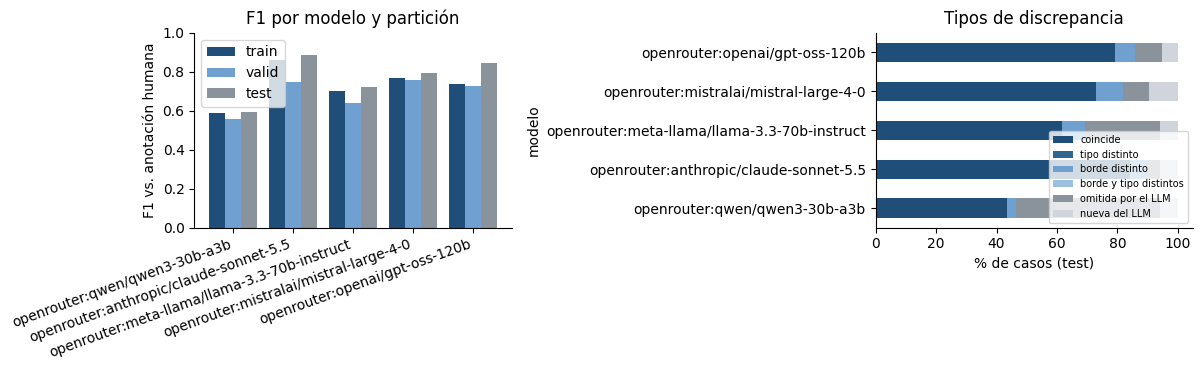

**Acuerdo entre LLMs (F1 entre pares)**

,openrouter:qwen/qwen3-30b-a3b,openrouter:anthropic/claude-sonnet-5.5,openrouter:meta-llama/llama-3.3-70b-instruct,openrouter:mistralai/mistral-large-4-0,openrouter:openai/gpt-oss-120b
openrouter:qwen/qwen3-30b-a3b,1.000,0.620,0.641,0.618,0.654
openrouter:anthropic/claude-sonnet-5.5,0.620,1.000,0.754,0.801,0.796
openrouter:meta-llama/llama-3.3-70b-instruct,0.641,0.754,1.000,0.792,0.769
openrouter:mistralai/mistral-large-4-0,0.618,0.801,0.792,1.000,0.813
openrouter:openai/gpt-oss-120b,0.654,0.796,0.769,0.813,1.000


In [ ]:
%%por_corpus
# Figuras de la comparación
COLS_MOD = ["#1f4e79", "#6fa0d0", "#8a929b", "#b4bcc5", "#2f6690", "#5c6670"]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
t = comp_llm.reset_index()
for k, s in enumerate(["train", "valid", "test"]):
    sub = t[t.split == s]
    axs[0].bar([x + k * 0.27 for x in range(len(sub))], sub["f1"], width=0.27,
               color=["#1f4e79", "#6fa0d0", "#8a929b"][k], label=s)
axs[0].set_xticks([x + 0.27 for x in range(len(ANOT))]); axs[0].set_xticklabels(list(ANOT), rotation=20, ha="right")
axs[0].set_ylabel("F1 vs. anotación humana"); axs[0].set_ylim(0, 1); axs[0].legend(); axs[0].set_title("F1 por modelo y partición")
disc_cols = ["coincide", "tipo distinto", "borde distinto", "borde y tipo distintos", "omitida por el LLM", "nueva del LLM"]
d = t[t.split == "test"].set_index("modelo")[disc_cols]
d.div(d.sum(axis=1), axis=0).mul(100).plot.barh(stacked=True, ax=axs[1],
    color=["#1f4e79", "#2f6690", "#6fa0d0", "#9cc0e0", "#8a929b", "#cfd5db"])
axs[1].set_xlabel("% de casos (test)"); axs[1].set_title("Tipos de discrepancia"); axs[1].legend(fontsize=7, loc="lower right")
for ax in axs: ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(DIR_F2 / "comparacion_llm.png", dpi=130); plt.show()

# Acuerdo entre LLMs (F1 de cada par de modelos, en todas las frases anotadas)
nombres = list(ANOT)
if len(nombres) > 1:
    acuerdo = pd.DataFrame(index=nombres, columns=nombres, dtype=float)
    for a in nombres:
        for b in nombres:
            pares = [(ANOT[a][s][i], ANOT[b][s][i]) for s in ANOT[a] for i in ANOT[a][s]]
            acuerdo.loc[a, b] = metricas_ner([x for x, _ in pares], [y for _, y in pares])["f1_micro"]
    display(Markdown("**Acuerdo entre LLMs (F1 entre pares)**")); display(acuerdo.round(3))
    acuerdo.to_csv(DIR_F2 / "acuerdo_entre_llms.csv", encoding="utf-8-sig")

### 2.2.5 Filtrado por votación y corpus depurado
Se aplican reglas fijas y conservadoras, **solo en train y valid**:

| Situación | Acción |
|---|---|
| ≥ `VOTOS_MIN` LLMs proponen la misma entidad (mismo inicio, fin y tipo) y no se solapa con ninguna entidad humana | **AÑADIR** (posible omisión humana) |
| ≥ `VOTOS_MIN` LLMs proponen una entidad que se solapa con una humana distinta, y menos de `VOTOS_MIN` LLMs apoyan la humana | **REEMPLAZAR** (corrección de tipo o de límites) |
| Ningún LLM propone nada que se solape con una entidad humana | **REVISAR** (posible falso positivo humano). No se borra automáticamente |
| Cualquier otro caso | Se mantiene la etiqueta humana |

Todas las propuestas se guardan en `cambios_propuestos.csv` para revisarlas a mano. Si `APLICAR_CAMBIOS = True`, AÑADIR y REEMPLAZAR se aplican al corpus depurado.

In [ ]:
%%por_corpus
import copy

def bio_desde_spans(n, spans):
    tags = ["O"] * n
    for ty, a, b in spans:
        tags[a] = f"B-{ty}"
        for k in range(a + 1, b + 1): tags[k] = f"I-{ty}"
    return tags

def consenso(frase_tags_llm, votos_min):
    votos = collections.Counter(sp for tags in frase_tags_llm for sp in set(spans_de(tags)))
    cand = sorted([sp for sp, v in votos.items() if v >= votos_min], key=lambda sp: (-votos[sp], -(sp[2] - sp[1])))
    elegidos = []
    for sp in cand:                       # sin solapamientos: gana el más votado (y luego el más largo)
        if all(sp[2] < e[1] or e[2] < sp[1] for e in elegidos): elegidos.append(sp)
    return elegidos, votos

cambios = []
CORPUS_DEP = copy.deepcopy(CORPUS)
solapa = lambda x, y: x[1] <= y[2] and y[1] <= x[2]
for s in ("train", "valid"):
    for i in IDX_F2.get(s, []):
        frase = CORPUS[s][i]; texto_f = " ".join(w for w, _ in frase)
        G = spans_de([t for _, t in frase])
        llm_tags = [ANOT[n][s][i] for n in ANOT if i in ANOT[n].get(s, {})]
        C, votos = consenso(llm_tags, VOTOS_MIN)
        nuevos = list(G)
        for c in C:
            if c in G: continue
            sol = [g for g in G if solapa(g, c)]
            desc = lambda sp: " ".join(w for w, _ in frase[sp[1]:sp[2] + 1]) + f" [{sp[0]}]"
            if not sol:
                accion = "AÑADIR"; nuevos.append(c)
            elif all(votos.get(g, 0) < VOTOS_MIN for g in sol):
                accion = "REEMPLAZAR"; nuevos = [g for g in nuevos if g not in sol] + [c]
            else:
                continue
            cambios.append({"split": s, "frase_idx": i, "accion": accion, "frase": texto_f[:250],
                            "humano": "; ".join(desc(g) for g in sol) or "—", "propuesta_llm": desc(c),
                            "votos": votos[c], "n_modelos": len(llm_tags)})
        for g in G:
            if not any(solapa(g, sp) for tags in llm_tags for sp in spans_de(tags)):
                cambios.append({"split": s, "frase_idx": i, "accion": "REVISAR", "frase": texto_f[:250],
                                "humano": " ".join(w for w, _ in frase[g[1]:g[2] + 1]) + f" [{g[0]}]",
                                "propuesta_llm": "ningún LLM la anota", "votos": 0, "n_modelos": len(llm_tags)})
        if APLICAR_CAMBIOS and sorted(nuevos) != sorted(G):
            nuevas_tags = bio_desde_spans(len(frase), nuevos)
            CORPUS_DEP[s][i] = [(w, t) for (w, _), t in zip(frase, nuevas_tags)]

cambios = pd.DataFrame(cambios)
cambios.to_csv(DIR_F2 / "cambios_propuestos.csv", index=False, encoding="utf-8-sig")
if len(cambios):
    display(cambios.groupby(["split", "accion"]).size().unstack(fill_value=0))
    display(cambios.head(15))
else:
    print("No hay cambios propuestos.")

#### ▸ Prostata

accion,AÑADIR,REEMPLAZAR,REVISAR
split,,,
train,31,38,5
valid,2,10,4


,split,frase_idx,accion,frase,humano,propuesta_llm,votos,n_modelos
0,train,52,REEMPLAZAR,Paciente remitido con dx de ca de próstata eivb ct2nxm1 Gleason 5+4 5 + 4 psa inicial de 45 ng/ ml dx en el año 2021 .,psa inicial de 45 ng/ ml [BIOMARCADOR],45 ng/ ml [BIOMARCADOR],3,5
1,train,190,AÑADIR,"Con DX ADENOCARCINOMA DE PROSTATA , Gleason 4+4 , ct4n1m0 , muy alto riesgo PSAI : 675 ng / m .",—,675 ng / m [BIOMARCADOR],3,5
2,train,190,AÑADIR,"Con DX ADENOCARCINOMA DE PROSTATA , Gleason 4+4 , ct4n1m0 , muy alto riesgo PSAI : 675 ng / m .",—,PSAI [BIOMARCADOR],2,5
3,train,199,AÑADIR,PSA : 0.30 ng / ml - ( 15-sep-2021 ) .,—,0.30 ng / ml [BIOMARCADOR],4,5
4,train,199,AÑADIR,PSA : 0.30 ng / ml - ( 15-sep-2021 ) .,—,PSA [BIOMARCADOR],3,5
5,train,207,AÑADIR,"Paciente con DX de ADENOCARCINOMA DE PROSTATA , Gleason 4+4 Gleason 4+4 4 + 4 , ct4n1m0 ct4n1m0 muy alto riesgo PSAI...",—,PSAI : 675 [BIOMARCADOR],3,5
6,train,207,AÑADIR,"Paciente con DX de ADENOCARCINOMA DE PROSTATA , Gleason 4+4 Gleason 4+4 4 + 4 , ct4n1m0 ct4n1m0 muy alto riesgo PSAI...",—,4 + 4 [GLEASON],2,5
7,train,229,REEMPLAZAR,1- Cito a simulación 3D 2- Se solicita valoración por oncología clínica 3- Se solicita valoración por psicología 4- ...,SBRT [DOSIS],SBRT [TRATAMIENTO],5,5
8,train,256,AÑADIR,"GLEASON SCORE 3+4 3 + 4 , PSA de 8 ng/dl PSA 8 ng/ml PSA mas alto reportado en HC 8 ng/dl 8 ng / dl .",—,8 ng / dl [BIOMARCADOR],3,5
9,train,256,REEMPLAZAR,"GLEASON SCORE 3+4 3 + 4 , PSA de 8 ng/dl PSA 8 ng/ml PSA mas alto reportado en HC 8 ng/dl 8 ng / dl .",PSA mas alto reportado en HC 8 ng/dl [BIOMARCADOR],8 ng/dl [BIOMARCADOR],3,5


## 2.3 Validación del corpus procesado
Se comprueba que:

1. **No hay frases compartidas** entre train, valid y test (fuga = 0).
2. **No hay duplicados** dentro de cada partición.
3. **El test no se ha modificado.**

También se comparan el LCS y el CBR del corpus original, del deduplicado y del depurado por los LLMs.

In [ ]:
%%por_corpus
dup_dep, _ = analisis_duplicados(CORPUS_DEP)
fuga = {k: v["frases"] for k, v in dup_dep["fuga"].items()}
duplic = {s: d["duplicados_mismo_texto"] for s, d in dup_dep["por_split"].items()}
test_igual = CORPUS_DEP["test"] == CORPUS["test"]
validacion = pd.DataFrame([
    {"comprobación": "Frases compartidas entre particiones", "resultado": sum(fuga.values()), "detalle": fuga,
     "ok": sum(fuga.values()) == 0},
    {"comprobación": "Duplicados dentro de cada partición", "resultado": sum(duplic.values()), "detalle": duplic,
     "ok": sum(duplic.values()) == 0},
    {"comprobación": "Test sin modificar (etiquetas humanas)", "resultado": test_igual, "detalle": "", "ok": test_igual},
]).set_index("comprobación")
display(validacion)

evolucion = pd.DataFrame({
    "original":                {**label_consistency_score(data),       **class_balance_ratio(data)},
    "deduplicado":             {**label_consistency_score(CORPUS),     **class_balance_ratio(CORPUS)},
    "depurado por LLMs (F2)":  {**label_consistency_score(CORPUS_DEP), **class_balance_ratio(CORPUS_DEP)},
})
display(Markdown("**Evolución de las métricas de calidad**")); display(evolucion)
evolucion.to_csv(DIR_F2 / "evolucion_LCS_CBR.csv", encoding="utf-8-sig")

#### ▸ Prostata

,resultado,detalle,ok
comprobación,,,
Frases compartidas entre particiones,0,"{'valid_en_train': 0, 'test_en_train': 0, 'test_en_valid': 0}",True
Duplicados dentro de cada partición,0,"{'train': 0, 'valid': 0, 'test': 0}",True
Test sin modificar (etiquetas humanas),True,,True


**Evolución de las métricas de calidad**

,original,deduplicado,depurado por LLMs (F2)
LCS,0.9527,0.9563,0.9532
LCS_frase,0.9637,1.0,1.0
LCS_tipo,0.9994,0.9995,0.9995
LCS_marcado,0.9059,0.913,0.9068
frases_repetidas,1047,0,0
expresiones_evaluadas_marcado,708,541,540
CBR,0.1948,0.1922,0.1932
tipo_min,EDAD,EDAD,EDAD
tipo_max,FECHA,FECHA,FECHA
menciones_min,246,197,198


### 2.3.1 Guardar resultados de la Fase 2

In [ ]:
%%por_corpus
# Guardar el corpus depurado, los prompts usados y un resumen de la Fase 2
(DIR_F2 / "corpus_depurado").mkdir(exist_ok=True)
for s, F in CORPUS_DEP.items(): guardar_bio(F, DIR_F2 / "corpus_depurado" / f"{s}.bio")
(DIR_F2 / "prompts.json").write_text(json.dumps({
    "version": VERSION_PROMPT, "modo": MODO_PROMPT, "sistema": SISTEMA_F2,
    "ejemplo_usuario": prompt_usuario(CORPUS["valid"][0]), "few_shot": [" ".join(w for w, _ in f) for f in FEW_SHOT],
    "modelos": [f"{p}:{m}" for p, m in MODELOS_LLM], "muestra": MUESTRA_F2, "votos_min": VOTOS_MIN,
    "aplicar_cambios": APLICAR_CAMBIOS}, ensure_ascii=False, indent=1), encoding="utf-8")
print("Fase 2 guardada en:", DIR_F2.resolve())
for p in sorted(DIR_F2.rglob("*")):
    if p.is_file(): print("  ", p.relative_to(DIR_F2))

#### ▸ Prostata

Fase 2 guardada en: /content/resultados/Prostata_20261023_0022/fase2
   acuerdo_entre_llms.csv
   cambios_propuestos.csv
   comparacion_llm.png
   corpus_depurado/test.bio
   corpus_depurado/train.bio
   corpus_depurado/valid.bio
   evolucion_LCS_CBR.csv
   llm_vs_humano.csv
   llm_vs_humano_por_tipo.csv
   prompts.json
   resumen_llamadas.csv


---
# 3. Comparación entre corpus: Próstata frente a Pulmón
Reúne en tablas y figuras comunes los resultados de las Fases 1 y 2 de los corpus de `CORPUS_A_PROCESAR`. Todo se guarda en `resultados/comparacion_<fecha>/`.

Los dos corpus usan esquemas de etiquetas distintos (10 tipos en Próstata, 16 en Pulmón), así que la comparación por tipo se hace solo con los **tipos homólogos** (3.3).

## 3.1 Fase 1: caracterización, calidad y línea base

In [ ]:
CORPUS_OK = [n for n in CORPUS_A_PROCESAR if "CORPUS" in ESTADO.get(n, {})]
DIR_CMP = Path("resultados") / f"comparacion_{EJECUCION}"
DIR_CMP.mkdir(parents=True, exist_ok=True)
COL_CORPUS = dict(zip(CORPUS_OK, ["#1f4e79", "#8a929b", "#6fa0d0", "#5c6670"]))

def _split3(d, f): return "/".join(str(f(d[s])) for s in ("train", "valid", "test") if s in d)

filas = {}
for n in CORPUS_OK:
    E = ESTADO[n]; dup_, cmp_ = E["dup"], E["comparacion"]
    orig, ded = cmp_[f"{n} (original)"], cmp_[f"{n} (deduplicado)"]
    fuga_ = dup_["fuga"]; rb = E.get("resultado_base")
    fila = {
        "Frases originales (train/valid/test)": _split3(E["data"], len),
        "% duplicados exactos (train/valid/test)": _split3(dup_["por_split"], lambda d: d["pct_duplicados_exactos"]),
        "% fuga valid→train": fuga_.get("valid_en_train", {}).get("pct"),
        "% fuga test→train": fuga_.get("test_en_train", {}).get("pct"),
        "% fuga test→valid": fuga_.get("test_en_valid", {}).get("pct"),
        "Frases con anotación contradictoria": f"{dup_['n_conflictos']} ({dup_['pct_conflictos_sobre_unicas']} %)",
        "Frases normalizadas (train/valid/test)": _split3(E["CORPUS"], len),
        "Tipos de entidad": ded["tipos de entidad"],
        "Entidades / 100 tokens": ded["entidades / 100 tokens"],
        "% tokens O": ded["% tokens O"],
        "Longitud mediana / p99 (train)": f"{ded['long. mediana (train)']} / {ded['long. p99 (train)']}",
        "Ratio de desbalance (máx/mín)": ded["ratio desbalance"],
        "Entropía normalizada": ded["entropía normalizada"],
        "CBR original → normalizado": f"{orig['CBR']} → {ded['CBR']}",
        "LCS original → normalizado": f"{orig['LCS']} → {ded['LCS']}",
        "LCS_tipo (normalizado)": ded["LCS_tipo"],
        "LCS_marcado (normalizado)": ded["LCS_marcado"],
    }
    if rb:
        f1t = {ty: d["f1"] for ty, d in rb["por_tipo"].items()}
        fila.update({"Baseline F1 micro (test)": rb["f1_micro"], "Baseline F1 macro (test)": rb["f1_macro"],
                     "Baseline P / R (test)": f"{rb['precision']} / {rb['recall']}",
                     "Mejor tipo (F1)": f"{max(f1t, key=f1t.get)} ({max(f1t.values())})",
                     "Peor tipo (F1)": f"{min(f1t, key=f1t.get)} ({min(f1t.values())})"})
    else:
        fila["Baseline F1 micro (test)"] = "no entrenado"
    filas[n] = fila
CMP_F1 = pd.DataFrame(filas)
CMP_F1.to_csv(DIR_CMP / "3_1_fase1_comparacion.csv", encoding="utf-8-sig")
CMP_F1

,Prostata
Frases originales (train/valid/test),3106/929/991
% duplicados exactos (train/valid/test),25.72/11.84/20.28
% fuga valid→train,87.41
% fuga test→train,68.92
% fuga test→valid,34.91
Frases con anotación contradictoria,38 (1.42 %)
Frases normalizadas (train/valid/test),1877/402/402
Tipos de entidad,10
Entidades / 100 tokens,11.3
% tokens O,75.33


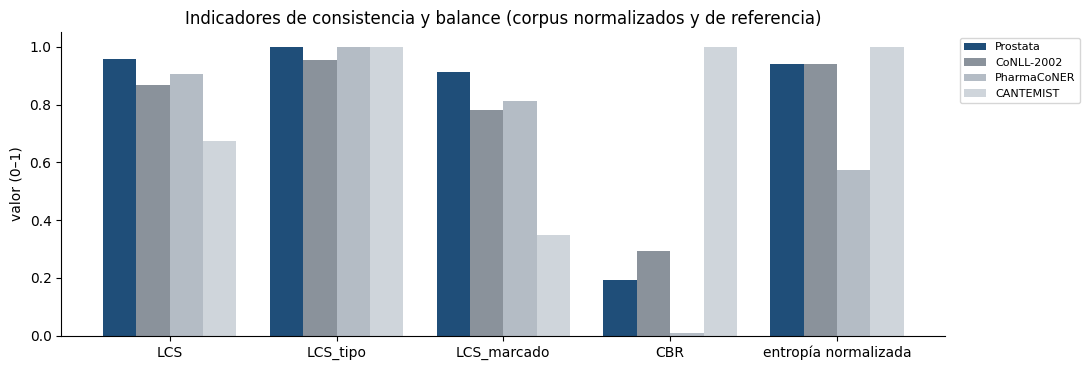

In [ ]:
# Figura: indicadores de calidad (0-1) de cada corpus normalizado, junto a los corpus de referencia
ind = ["LCS", "LCS_tipo", "LCS_marcado", "CBR", "entropía normalizada"]
tabla_ind = {n: ESTADO[n]["comparacion"][f"{n} (deduplicado)"] for n in CORPUS_OK}
tabla_ind.update({r: pd.Series(p) for r, p in _PERFIL_REF.items()})
tabla_ind = pd.DataFrame({k: v[ind] for k, v in tabla_ind.items()}).astype(float)
cols = [COL_CORPUS.get(c, g) for c, g in zip(tabla_ind.columns, ["#1f4e79", "#8a929b"] + ["#b4bcc5", "#cfd5db", "#e3e7eb"] * 2)]
ax = tabla_ind.plot.bar(figsize=(11, 3.8), color=cols, width=0.8)
ax.set_ylim(0, 1.05); ax.set_ylabel("valor (0–1)"); ax.set_title("Indicadores de consistencia y balance (corpus normalizados y de referencia)")
ax.tick_params(axis="x", rotation=0); ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1)); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(DIR_CMP / "3_1_indicadores_calidad.png", dpi=130); plt.show()
tabla_ind.to_csv(DIR_CMP / "3_1_indicadores_calidad.csv", encoding="utf-8-sig")

## 3.2 Fase 2: rendimiento de los LLMs y depuración
F1, precisión, recall y cobertura de cada LLM frente a la anotación humana del **test** de cada corpus, el número de cambios propuestos por votación y la evolución del LCS y el CBR.

**Métricas de cada LLM en el test (frente a la anotación humana)**

corpus                                        Prostata                  \
                                             cobertura     f1 f1_macro   
modelo                                                                   
openrouter:qwen/qwen3-30b-a3b                    0.494  0.592    0.540   
openrouter:anthropic/claude-sonnet-5.5           0.950  0.885    0.885   
openrouter:meta-llama/llama-3.3-70b-instruct     0.738  0.724    0.693   
openrouter:mistralai/mistral-large-4-0           0.906  0.794    0.783   
openrouter:openai/gpt-oss-120b                   0.906  0.845    0.835   

corpus                                                         
                                             precision recall  
modelo                                                         
openrouter:qwen/qwen3-30b-a3b                    0.822  0.462  
openrouter:anthropic/claude-sonnet-5.5           0.877  0.894  
openrouter:meta-llama/llama-3.3-70b-instruct     0.808  0.656  
openrouter:mistralai/mistral-large-4-0           0.782  0.806  
openrouter:openai/gpt-oss-120b                   0.854  0.838

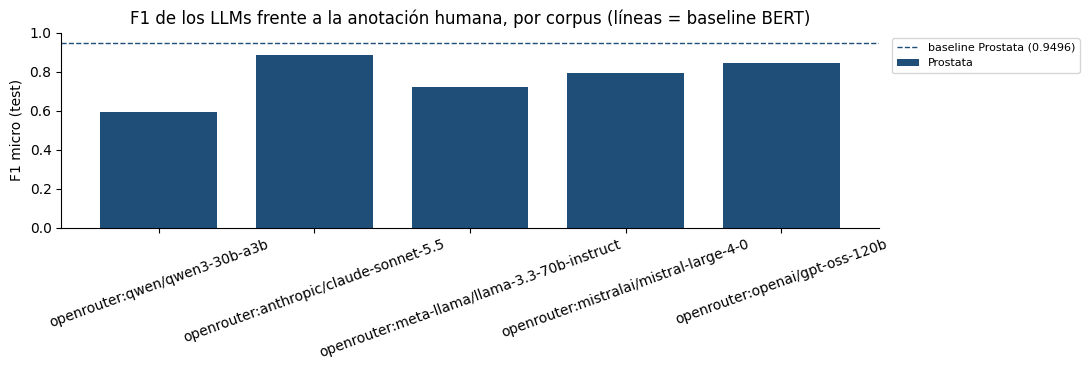

**Resumen de la Fase 2 por corpus**

,Prostata
Frases anotadas por modelo,175
Minutos totales de anotación,10.0
Costo OpenRouter (USD),1.346
Mejor LLM (F1 test),openrouter:anthropic/claude-sonnet-5.5 (0.8854)
Acuerdo medio entre LLMs (F1),0.726
AÑADIR,33
REEMPLAZAR,48
REVISAR,9
LCS normalizado → depurado,0.9563 → 0.9532
LCS_marcado normalizado → depurado,0.913 → 0.9068


In [ ]:
CORPUS_F2 = [n for n in CORPUS_OK if "comp_llm" in ESTADO[n] and len(ESTADO[n]["comp_llm"])]
if not CORPUS_F2:
    print("Ningún corpus tiene resultados de la Fase 2.")
else:
    t = pd.concat({n: ESTADO[n]["comp_llm"].xs("test", level="split")[["precision", "recall", "f1", "f1_macro", "cobertura"]]
                   for n in CORPUS_F2}, names=["corpus", "modelo"])
    CMP_LLM = t.unstack("corpus").swaplevel(0, 1, axis=1).sort_index(axis=1, level=0)
    CMP_LLM.to_csv(DIR_CMP / "3_2_llm_test_por_corpus.csv", encoding="utf-8-sig")
    display(Markdown("**Métricas de cada LLM en el test (frente a la anotación humana)**")); display(CMP_LLM.round(3))

    fig, ax = plt.subplots(figsize=(11, 3.8))
    f1 = t["f1"].unstack("corpus")
    f1.plot.bar(ax=ax, color=[COL_CORPUS[n] for n in f1.columns], width=0.75)
    for n in f1.columns:
        rb = ESTADO[n].get("resultado_base")
        if rb: ax.axhline(rb["f1_micro"], ls="--", lw=1, color=COL_CORPUS[n], label=f"baseline {n} ({rb['f1_micro']})")
    ax.set_ylim(0, 1); ax.set_ylabel("F1 micro (test)"); ax.set_xlabel("")
    ax.set_title("F1 de los LLMs frente a la anotación humana, por corpus (líneas = baseline BERT)")
    ax.tick_params(axis="x", rotation=20); ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1)); ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout(); plt.savefig(DIR_CMP / "3_2_f1_llm_por_corpus.png", dpi=130); plt.show()

    res = {}
    for n in CORPUS_F2:
        E = ESTADO[n]; ev = E["evolucion"]; cb = E["cambios"]
        acc = cb["accion"].value_counts() if len(cb) else pd.Series(dtype=int)
        r = E["resumen_llm"]
        res[n] = {"Frases anotadas por modelo": int(r["frases"].max()),
                  "Minutos totales de anotación": round(r["segundos"].sum() / 60, 1),
                  "Costo OpenRouter (USD)": round(r["costo USD"].sum(), 3) if "costo USD" in r else None,
                  "Mejor LLM (F1 test)": f"{t.loc[n, 'f1'].idxmax()} ({t.loc[n, 'f1'].max()})",
                  "Acuerdo medio entre LLMs (F1)": round(E["acuerdo"].where(~pd.DataFrame(
                      [[a == b for b in E["acuerdo"].columns] for a in E["acuerdo"].index],
                      index=E["acuerdo"].index, columns=E["acuerdo"].columns)).stack().mean(), 3) if "acuerdo" in E else None,
                  "AÑADIR": int(acc.get("AÑADIR", 0)), "REEMPLAZAR": int(acc.get("REEMPLAZAR", 0)),
                  "REVISAR": int(acc.get("REVISAR", 0)),
                  "LCS normalizado → depurado": f"{ev.loc['LCS', 'deduplicado']} → {ev.loc['LCS', 'depurado por LLMs (F2)']}",
                  "LCS_marcado normalizado → depurado": f"{ev.loc['LCS_marcado', 'deduplicado']} → {ev.loc['LCS_marcado', 'depurado por LLMs (F2)']}",
                  "CBR normalizado → depurado": f"{ev.loc['CBR', 'deduplicado']} → {ev.loc['CBR', 'depurado por LLMs (F2)']}",
                  "Validación 2.3 superada": bool(E["validacion"]["ok"].all())}
    CMP_F2 = pd.DataFrame(res)
    CMP_F2.to_csv(DIR_CMP / "3_2_fase2_resumen.csv", encoding="utf-8-sig")
    display(Markdown("**Resumen de la Fase 2 por corpus**")); display(CMP_F2)

## 3.3 Tipos homólogos
Tipos que representan el mismo concepto clínico en los dos esquemas de anotación. Para cada uno se comparan las menciones en train, el F1 del baseline y el F1 del mejor LLM en el test. Puedes editar `HOMOLOGOS` para añadir o quitar pares.

In [ ]:
HOMOLOGOS = {                       # concepto: (tipo en Próstata, tipo en Pulmón)
    "Cáncer / neoplasia": ("CANCER", "CANCER_CONCEPT"),
    "Fecha":              ("FECHA", "DATE"),
    "Fármaco":            ("MEDICAMENTO", "DRUG"),
    "Cirugía":            ("CIRUGIA", "SURGERY"),
    "Estadificación TNM": ("TNM", "TNM"),
}
ORDEN = {"Prostata": 0, "Pulmon": 1}
filas = []
for concepto, tipos in HOMOLOGOS.items():
    fila = {"concepto": concepto}
    for n in CORPUS_OK:
        ty = tipos[ORDEN.get(n, 0)]; E = ESTADO[n]
        fila[f"{n}: tipo"] = ty
        fila[f"{n}: menciones train"] = sum(1 for f in E["CORPUS"]["train"] for e in entidades(f) if e[0] == ty)
        rb = E.get("resultado_base")
        fila[f"{n}: F1 baseline"] = rb["por_tipo"].get(ty, {}).get("f1") if rb else None
        ct = E.get("comp_tipo")
        if ct is not None and len(ct):
            sub = ct[(ct.split == "test") & (ct.tipo == ty)]
            fila[f"{n}: F1 mejor LLM"] = f"{sub.f1.max()} ({sub.loc[sub.f1.idxmax(), 'modelo']})" if len(sub) else None
    filas.append(fila)
CMP_HOM = pd.DataFrame(filas).set_index("concepto")
CMP_HOM.to_csv(DIR_CMP / "3_3_tipos_homologos.csv", encoding="utf-8-sig")
CMP_HOM

,Prostata: tipo,Prostata: menciones train,Prostata: F1 baseline,Prostata: F1 mejor LLM
concepto,,,,
Cáncer / neoplasia,CANCER,969,0.9685,0.9474 (openrouter:mistralai/mistral-large-4-0)
Fecha,FECHA,1025,0.9955,0.9855 (openrouter:anthropic/claude-sonnet-5.5)
Fármaco,MEDICAMENTO,283,0.9697,0.9524 (openrouter:anthropic/claude-sonnet-5.5)
Cirugía,CIRUGIA,219,0.9091,0.8571 (openrouter:anthropic/claude-sonnet-5.5)
Estadificación TNM,TNM,311,0.9212,1.0 (openrouter:anthropic/claude-sonnet-5.5)


## 3.4 Exportar resultados
Comprime la carpeta `resultados/` (una carpeta por corpus, la de comparación y `registro_experimentos.csv`) en `resultados_<fecha>.zip` y lo descarga. **Ese zip es el que hay que compartir para analizar los resultados.**

In [ ]:
import shutil
if Path("registro_experimentos.csv").exists(): shutil.copy("registro_experimentos.csv", "resultados/registro_experimentos.csv")
if Path("cache_llm.jsonl").exists(): shutil.copy("cache_llm.jsonl", "resultados/cache_llm.jsonl")   # respuestas crudas de los LLMs
excluir = {"modelos"}                                                # los pesos del baseline pesan ~0,5 GB por corpus
zip_path = Path(f"resultados_{EJECUCION}.zip")
import zipfile
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in Path("resultados").rglob("*"):
        if p.is_file() and not (set(p.relative_to("resultados").parts) & excluir):
            z.write(p, p.relative_to("resultados"))
print(f"{zip_path} ({zip_path.stat().st_size / 1e6:.1f} MB)")
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    print("Fuera de Colab: el zip queda en", zip_path.resolve())

resultados_20261023_0022.zip (0.7 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# Siguiente paso: Fase 3

El corpus depurado (`fase2/corpus_depurado/`) se entrena con la misma función del baseline, para que la comparación sea justa (mismo modelo, hiperparámetros, semilla y test):

```python
%%por_corpus
m_dep, pred_dep, registro = entrenar_ner(CORPUS_DEP, f"depurado_{NOMBRE}", modelo="PlanTL-GOB-ES/bsc-bio-ehr-es")
m_xlmr, pred_xlmr, registro = entrenar_ner(CORPUS_DEP, f"depurado_xlmr_{NOMBRE}", modelo="xlm-roberta-base")
```

Cada entrenamiento añade una fila a `registro_experimentos.csv`, que será la base de las tablas comparativas de la Fase 4.

**Antes de procesar todo el corpus:**

1. Prueba con la muestra y 2 o 3 modelos.
2. Revisa a mano unas 50 filas de `cambios_propuestos.csv` para estimar cuántas correcciones son acertadas, y documenta ese porcentaje.
3. Ajusta las definiciones de la guía o `VOTOS_MIN` y sube `VERSION_PROMPT`.
4. Pon `MUESTRA_F2 = None` para anotar todo.